In [ ]:
#@title

from IPython.display import display, HTML

display(HTML("""
<div id="top" style="
    background: #0b1020;
    color: #e8edff;
    padding: 28px;
    border-radius: 12px;
    font-family: Arial, sans-serif;
    font-size: 14px;
    line-height: 1.8;
    width: 100%;
    box-sizing: border-box;
">
    <h1 style="
        color: #ffffff;
        font-size: 27px;
        line-height: 1.35;
        margin: 0 0 24px 0;
    ">
        Лабораторная работа 01 — статистическое исследование объектов Gaia DR3
    </h1>

    <p style="margin: 0 0 14px 0;">
        <strong style="color: #b9a8ff;">Тема:</strong>
        как распределены видимая яркость, цвет и параллакс объектов Gaia
        и что меняется при выборе только самых ярких объектов.
    </p>

    <p style="margin: 0 0 28px 0;">
        <strong style="color: #b9a8ff;">Команда:</strong>
        три инфохимика · общая аналитическая часть для последующего оформления дизайнерами
    </p>

    <p style="color: #c6d2ff; font-size: 19px; font-weight: 600; margin-bottom: 12px;">
        В работе исследуются три случайные величины:
    </p>

    <ol style="padding-left: 24px; margin: 0 0 26px 0;">
        <li style="padding: 3px 0;">
            видимая звёздная величина
            <code style="color: #c4b5fd; background: #1b2440; padding: 2px 6px; border-radius: 4px;">G</code>
            — участник 1;
        </li>
        <li style="padding: 3px 0;">
            цвет
            <code style="color: #c4b5fd; background: #1b2440; padding: 2px 6px; border-radius: 4px;">BP − RP</code>
            — участник 2;
        </li>
        <li style="padding: 3px 0;">измеренный параллакс — участник 3.</li>
    </ol>

    <div style="
        background: #131c33;
        border-left: 3px solid #8b9dff;
        padding: 16px 18px;
        border-radius: 0 8px 8px 0;
        margin: 0 0 24px 0;
    ">
        <p style="color: #c6d2ff; font-size: 18px; font-weight: 600; margin: 0 0 8px 0;">
            Главный вопрос работы
        </p>
        <p style="margin: 0;">
            Главный вопрос работы: можно ли по случайной выборке объектов Gaia судить о всей выбранной базе и как меняется вывод, если выбирать объекты не случайно, а по яркости.
        </p>
    </div>

    <div style="
        background: #171b32;
        border: 1px solid #343b60;
        padding: 16px 18px;
        border-radius: 8px;
    ">
        <p style="color: #c4b5fd; font-size: 17px; font-weight: 600; margin: 0 0 8px 0;">
            Важно про область вывода.
        </p>
        <p style="margin: 0;">
            Генеральная совокупность в этой лабораторной — конечная рабочая база из 10 000 объектов Gaia DR3. Это не все звёзды Вселенной и не все объекты Млечного Пути. Поэтому выводы относятся к этой базе и к способу её формирования.
        </p>
    </div>
</div>
"""))

In [ ]:
# @title
from IPython.display import display, HTML

display(HTML("""
<div style="
    background: #111827;
    color: #F8FAFC;
    padding: 20px 24px;
    border-left: 5px solid #A78BFA;
    border-radius: 10px;
    font-family: Arial, sans-serif;
    box-sizing: border-box;
">
    <h1 style="
        color: #F8FAFC;
        margin: 0;
        font-size: 28px;
        font-weight: 700;
        line-height: 1.5;
    ">
        Оглавление
    </h1>
</div>
"""))

## Спринт 1 — статистическое исследование

1. [Данные и способ их получения](#scrollTo=P696gGLiHgzm)
2. [Что в работе считается случайной величиной](#scrollTo=bifbY3pFRBLI&line)
3. [Случайная величина 01 — видимая звёздная величина G](#scrollTo=vVpQ97tmTNPO&line)
4. [Случайная величина 02 — цвет BP − RP](#scrollTo=WVZ32rZaWUM0&line)
5. [Случайная величина 03 — измеренный параллакс](#scrollTo=Du3q5SfGf7CI&line)
6. [Зависимость между тремя величинами](#scrollTo=5Nz9obxigDf9&line)
7. [Генеральная совокупность, выборки и состоятельность оценок](#scrollTo=69PFOIvTgJFN&line)
8. [Проверка статистических гипотез](#scrollTo=Z0B2vmdNgNp7&line)
9. [Эксперимент: что меняется при выборе самых ярких объектов](#scrollTo=RbbL6zxygUaq&line)

## Спринт 2 — генераторы случайных величин

10. [Зачем нужен генератор](#scrollTo=mS4-NF-vgaNK&line)
11. [Математическое описание алгоритмов](#scrollTo=XoH_P8o_gfum&line)
12. [Автоматические проверки генераторов](#scrollTo=Wiq5NkKmgsPx&line)

## Итоги

13. [Итоговые выводы](#scrollTo=8VdXGaagdv40)
14. [Карта требований лабораторной работы](#scrollTo=NbxfodBWdl33)
15. [Литература и источники](#scrollTo=yM1b_5ePdgqA)

In [ ]:
# @title
from IPython.display import display, HTML

display(HTML("""
<div id="data" style="
    background: #111827;
    color: #F8FAFC;
    padding: 20px 24px;
    border: 1px solid #475569;
    border-left: 5px solid #A78BFA;
    border-radius: 10px;
    font-family: Arial, sans-serif;
    box-sizing: border-box;
">
    <h2 style="
        color: #F8FAFC;
        margin: 0;
        font-size: 23px;
        font-weight: 700;
        line-height: 1.5;
    ">
        1. Данные и способ их получения
    </h2>
</div>
"""))

<a id="data"></a>
Источник данных — официальный архив **Gaia Data Release 3**, таблица `gaiadr3.gaia_source` [1, 2].

```sql
SELECT source_id, random_index, ra, dec, phot_g_mean_mag, bp_rp,
       parallax, parallax_error, ruwe, phot_g_mean_flux_over_error
FROM gaiadr3.gaia_source
WHERE random_index < 20000
  AND phot_g_mean_mag IS NOT NULL
  AND bp_rp IS NOT NULL
  AND parallax IS NOT NULL
ORDER BY random_index
```

Для анализа используем 10 000 объектов с заполненными значениями G, BP − RP и параллакса. Объекты упорядочены по random_index — случайному индексу каталога. Поэтому первые строки в таком порядке позволяют получить случайный поднабор объектов, у которых доступны все три характеристики.

Мы ограничили объём десятью тысячами строк, чтобы многократно повторять расчёты и сравнивать выборки разного размера без обработки всего каталога. Само число 10 000 не гарантирует, что наша база точно представляет все звёзды: на её состав влияют возможности наблюдений Gaia и требование наличия трёх измерений.

При повторной проверке 26 октября 2026 года запрос выше вернул 14 932 подходящие записи. Однако в текущий ноутбук загружается уже подготовленный файл gaia_team.csv, содержащий 10 000 строк. Копия CSV в код ноутбука не встроена, поэтому для запуска нужен этот отдельный файл.

Далее эти 10 000 строк считаем конечной генеральной совокупностью для наших вычислительных экспериментов. Из неё будем многократно выбирать меньшие группы и сравнивать их характеристики с известными характеристиками всей рабочей базы.
Отрицательные измеренные параллаксы не удаляем. Из-за ошибок измерения оценка параллакса может оказаться отрицательной, но это не означает отрицательного физического расстояния. Удаление таких значений может смещать выборку, поэтому сохраняем их при анализе [3].

In [ ]:
# @title
from IPython.display import display, HTML

display(HTML("""
<div style="font-family: Arial, sans-serif; margin: 16px 0;">
<table style="
    width: 100%;
    border-collapse: separate;
    border-spacing: 0;
    border-radius: 10px;
    overflow: hidden;
    border: 1px solid #D8D4F0;
    font-size: 14px;
    color: #1F2937;
">
<thead>
<tr style="background: #111827; color: #F8FAFC;">
    <th style="padding: 14px; text-align: left;">Столбец</th>
    <th style="padding: 14px; text-align: left;">Простое объяснение</th>
    <th style="padding: 14px; text-align: left;">Единицы</th>
</tr>
</thead>
<tbody>
<tr style="background: #F5F3FF;">
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;"><code>phot_g_mean_mag</code></td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">Видимая звёздная величина G; чем меньше число, тем ярче объект</td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">mag</td>
</tr>
<tr style="background: #FFFFFF;">
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;"><code>bp_rp</code></td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">Разность синего и красного каналов; большее значение обычно означает более красный цвет</td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">mag</td>
</tr>
<tr style="background: #F5F3FF;">
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;"><code>parallax</code></td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">Измеренное годовое угловое смещение объекта из-за движения Земли</td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">mas</td>
</tr>
<tr style="background: #FFFFFF;">
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;"><code>parallax_error</code></td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">Стандартная ошибка измерения параллакса</td>
    <td style="padding: 12px; border-bottom: 1px solid #E5E7EB;">mas</td>
</tr>
<tr style="background: #F5F3FF;">
    <td style="padding: 12px;"><code>ruwe</code></td>
    <td style="padding: 12px;">Показатель качества астрометрического решения</td>
    <td style="padding: 12px;">Без единицы</td>
</tr>
</tbody>
</table>
</div>
"""))

Столбец,Простое объяснение,Единицы
phot_g_mean_mag,"Видимая звёздная величина G; чем меньше число, тем ярче объект",mag
bp_rp,Разность синего и красного каналов; большее значение обычно означает более красный цвет,mag
parallax,Измеренное годовое угловое смещение объекта из-за движения Земли,mas
parallax_error,Стандартная ошибка измерения параллакса,mas
ruwe,Показатель качества астрометрического решения,Без единицы


**Получение трех величин**

Все три характеристики взяты из таблицы `gaiadr3.gaia_source`, но получены они разными способами [1, 2]:

- `phot_g_mean_mag` — звёздная величина G, рассчитанная по среднему потоку света в широкой полосе G;
- `bp_rp` — разность звёздных величин в синем и красном фотометрических каналах Gaia;
- `parallax` — измеренный параллакс, полученный при обработке повторных наблюдений положения объекта.

**Условия наблюдений и ограничения**

Gaia DR3 использует наблюдения с 25 июля 2014 года по 28 мая 2017 года — всего 34 месяца [10]. Это космические наблюдения, поэтому условия наземной съёмки, например высота телескопа над уровнем моря, к нашим данным напрямую не относятся.

На наблюдаемый свет влияют температура и химический состав атмосферы звезды, расстояние до неё и межзвёздная пыль. Температура влияет на распределение энергии по спектру, химический состав — на спектральные линии, а пыль ослабляет свет и изменяет наблюдаемый цвет. Точность измерений также зависит от яркости объекта и особенностей его наблюдений [11].

В нашей таблице нет отдельных данных о температуре, составе и количестве пыли для каждого объекта, поэтому эти факторы помогают объяснить возможные причины различий, но их влияние мы здесь отдельно не измеряем.

В коде проверяются заполненность трёх основных столбцов и отсутствие повторных `source_id`. Дополнительные ограничения по `ruwe` и ошибке параллакса не вводятся. Следовательно, в базе остаются измерения с разной точностью – это нужно учитывать при обсуждении результатов.

In [ ]:
#@title Библиотеки и оформление графиков { display-mode: "form" }
import base64, hashlib, io, json, math, time, unittest, zlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special

OUT = Path('gaia_team_results')
OUT.mkdir(exist_ok=True)
SEED = 20261020
ALPHA = 0.05

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,

    # Космическая палитра
    'figure.facecolor': '#0b1020',
    'axes.facecolor': '#131b30',
    'savefig.facecolor': '#0b1020',
    'text.color': '#edf3ff',
    'axes.labelcolor': '#edf3ff',
    'axes.edgecolor': '#34415f',
    'xtick.color': '#edf3ff',
    'ytick.color': '#edf3ff',

    # Сетка и границы
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#34415f',
    'grid.alpha': 0.45,
    'grid.linestyle': '--',

    'figure.dpi': 120,
    'savefig.dpi': 160,
})

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
COLORS = {
    'G': '#7AA2F7',          # голубой
    'BP−RP': '#7EE0C3',      # бирюзовый
    'Параллакс': '#F7768E',  # кораллово-розовый
    'mean': '#E0AF68',       # золотистый
    'median': '#BB9AF7',     # фиолетовый
    'bright': '#FF79C6'      # ярко-розовый
}

In [ ]:
# @title Загрузка общей таблицы Gaia DR3

import io
import hashlib
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML

file_path = Path("gaia_team.csv")

if file_path.exists():
    filename = file_path.name
    raw_bytes = file_path.read_bytes()
else:
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
    raw_bytes = uploaded[filename]

raw = pd.read_csv(
    io.BytesIO(raw_bytes),
    dtype={"source_id": "string"}
)

PROVENANCE = {
    "catalogue": "Gaia DR3",
    "table": "gaiadr3.gaia_source",
    "query": """SELECT source_id, random_index, ra, dec, phot_g_mean_mag, bp_rp,
       parallax, parallax_error, ruwe, phot_g_mean_flux_over_error
FROM gaiadr3.gaia_source
WHERE random_index < 20000
  AND phot_g_mean_mag IS NOT NULL
  AND bp_rp IS NOT NULL
  AND parallax IS NOT NULL
ORDER BY random_index""",
    "retrieved_utc": "2026-10-18",
    "raw_sha256": hashlib.sha256(raw_bytes).hexdigest()
}

display(HTML(f"""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    background: #F5F3FF;
    border-left: 4px solid #8B7BD8;
    border-radius: 8px;
    padding: 12px 16px;
    line-height: 1.8;
">
    <div><b>Файл прочитан:</b> {filename}</div>
    <div><b>Размер таблицы:</b> {raw.shape}</div>
    <div><b>Столбцы:</b> {list(raw.columns)}</div>
</div>
"""))

In [ ]:
#@title Подготовка данных и контроль качества

main_columns = ['phot_g_mean_mag', 'bp_rp', 'parallax']

for column in raw.columns:
    if column != 'source_id':
        raw[column] = pd.to_numeric(raw[column], errors='coerce')

valid = np.isfinite(raw[main_columns].to_numpy(dtype=float)).all(axis=1)
prepared = raw.loc[valid].copy()

duplicates = int(prepared['source_id'].duplicated().sum())

if duplicates:
    raise ValueError(f'Повторные source_id: {duplicates}')

if len(prepared) < 10000:
    raise ValueError('В выгрузке меньше 10 000 полных строк.')

df = prepared.sort_values(
    'random_index', kind='stable'
).head(10000).reset_index(drop=True)

N = len(df)

df.to_csv(OUT/'gaia_team.csv', index=False)

PROVENANCE['team_rows'] = N
PROVENANCE['selection'] = 'First 10000 complete rows ordered by archive random_index'

(OUT/'provenance.json').write_text(
    json.dumps(PROVENANCE, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

(OUT/'gaia_query.sql').write_text(
    PROVENANCE['query'],
    encoding='utf-8'
)

quality = pd.DataFrame({
    'Проверка': [
       'Строк в загруженном CSV',
'Полных строк в загруженном CSV',
        'Строк в рабочей базе',
        'Повторных source_id',
        'Отрицательных параллаксов'
    ],
    'Результат': [
        len(raw),
        len(prepared),
        N,
        duplicates,
        int((df.parallax < 0).sum())
    ]
})

quality.to_csv(OUT/'data_quality.csv', index=False)

# Оформление таблицы контроля качества
from IPython.display import display, HTML
from html import escape

rows_html = ''

for i, row in quality.iterrows():
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'
    rows_html += f"""
    <tr style="background:{bg};">
        <td style="padding:12px 14px; border-bottom:1px solid #E5E7EB;">
            {escape(str(row['Проверка']))}
        </td>
        <td style="padding:12px 14px; border-bottom:1px solid #E5E7EB;">
            {escape(str(row['Результат']))}
        </td>
    </tr>
    """

display(HTML(f"""
<div style="font-family:Arial,sans-serif; margin:16px 0;">
<table style="
    width:100%;
    border-collapse:separate;
    border-spacing:0;
    border-radius:10px;
    overflow:hidden;
    border:1px solid #D8D4F0;
    font-size:14px;
    color:#1F2937;
">
    <thead>
        <tr style="background:#111827; color:#F8FAFC;">
            <th style="padding:14px; text-align:left; border-bottom:1px solid #475569;">
                Проверка
            </th>
            <th style="padding:14px; text-align:left; border-bottom:1px solid #475569;">
                Результат
            </th>
        </tr>
    </thead>
    <tbody>
        {rows_html}
    </tbody>
</table>
</div>
"""))

Проверка,Результат
Строк в загруженном CSV,10000
Полных строк в загруженном CSV,10000
Строк в рабочей базе,10000
Повторных source_id,0
Отрицательных параллаксов,2345


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
2. Что в работе считается случайной величиной
</h2></div>
"""))

<a id="random-variables"></a>

В таблице уже записаны результаты измерений. Случайный опыт состоит в том, что мы равновероятно выбираем один объект из рабочей базы.

Обозначим номер выбранной строки через $I$. Каждая из 10 000 строк имеет одинаковую вероятность выбора:

$$
P(I=i)=\frac{1}{N}, \qquad N=10000.
$$

После выбора смотрим характеристики попавшегося объекта:

$$
G=G_I,\qquad C=(BP-RP)_I,\qquad \Pi=\mathrm{parallax}_I.
$$

До выбора неизвестно, какая строка попадётся и какие значения мы получим. После выбора все три значения можно прочитать в таблице. Именно случайный выбор объекта задаёт здесь случайные величины.

Ошибки измерений — отдельная причина неопределённости. Даже если бы все характеристики были измерены совершенно точно, случайный выбор объекта из неоднородной базы всё равно давал бы случайные значения.

Наше объяснение относится к выбору из этих 10 000 записей. Оно не означает, что распределения в нашей базе совпадают с распределениями всех звёзд.

<a id="helpers"></a>
### Общие определения статистик и моделей

Для каждой величины считаются среднее, медиана, дисперсия, стандартное отклонение, квартили, асимметрия и эксцесс. Дисперсия с делителем (N) описывает разброс всей конечной базы, а дисперсия с делителем (N-1) — стандартная исправленная оценка по выборке:

$$
\mu_N=\frac1N\sum_{i=1}^{N}x_i,
\qquad
v_N=\frac1N\sum_{i=1}^{N}(x_i-\mu_N)^2,
\qquad
s^2=\frac1{n-1}\sum_{i=1}^{n}(x_i-\bar x)^2.
$$

Для формы распределения сравниваются нормальная модель, распределение Лапласа и асимметричная нормальная модель. Кроме того, для конечной базы всегда существует точное **эмпирическое распределение**: каждая строка имеет вероятность (1/N). Параметрические модели являются приближениями, а эмпирическое распределение точно описывает случайный выбор из этой базы.
*Параметрические распределения и статистические функции рассчитываются с использованием SciPy [6].*


In [ ]:

#@title Общие функции анализа и построения графиков
FEATURES = [
    {'key':'G', 'column':'phot_g_mean_mag', 'label':'G', 'long':'Видимая звёздная величина G', 'unit':'mag', 'color':COLORS['G']},
    {'key':'BP−RP', 'column':'bp_rp', 'label':'BP − RP', 'long':'Показатель цвета BP − RP', 'unit':'mag', 'color':COLORS['BP−RP']},
    {'key':'Параллакс', 'column':'parallax', 'label':'Параллакс', 'long':'Измеренный параллакс', 'unit':'mas', 'color':COLORS['Параллакс']},
]

def holm_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues)
    adjusted_sorted = np.minimum(1.0, np.maximum.accumulate(
        pvalues[order] * (len(pvalues) - np.arange(len(pvalues)))))
    adjusted = np.empty_like(pvalues)
    adjusted[order] = adjusted_sorted
    return adjusted

def describe_feature(values, unit, label):
    a = np.asarray(values, dtype=float)
    q1, med, q3 = np.quantile(a, [.25, .5, .75])
    iqr = q3-q1
    flags = (a < q1-1.5*iqr) | (a > q3+1.5*iqr)
    return pd.DataFrame({
        'Показатель':['Число объектов','Среднее','Медиана','Дисперсия базы (N)','Исправленная дисперсия','Стандартное отклонение',
                      'Минимум','Q1','Q3','Максимум','IQR','Асимметрия','Эксцесс','Отмечено правилом 1.5 IQR'],
        'Значение':[len(a),a.mean(),med,a.var(ddof=0),a.var(ddof=1),a.std(ddof=1),a.min(),q1,q3,a.max(),iqr,
                    stats.skew(a,bias=False),stats.kurtosis(a,bias=False),int(flags.sum())],
        'Единицы':[ 'объектов',unit,unit,unit+'²',unit+'²',unit,unit,unit,unit,unit,unit,
                    'безразмерная','безразмерный','объектов']
    }), flags

def fit_models_train_test(values, key):
    a = np.asarray(values, dtype=float)
    # Explicit seeds keep the train/test split reproducible across Python processes.
    seed_by_key = {'G':1101, 'BP−RP':1102, 'Параллакс':1103}[key]
    idx = np.random.default_rng(SEED+seed_by_key).permutation(len(a))
    n_train = int(.7*len(a))
    train, test = a[idx[:n_train]], a[idx[n_train:]]
    specs = {'Нормальная': stats.norm, 'Лапласа': stats.laplace, 'Асимметричная нормальная': stats.skewnorm}
    rows=[]; fitted={}
    for name, dist in specs.items():
        params = tuple(float(v) for v in dist.fit(train))
        fitted[name] = (dist, params)
        loglik = float(dist.logpdf(train, *params).sum())
        pcount = len(params)
        result = stats.kstest(test, dist.cdf, args=params)
        density = np.maximum(dist.pdf(test, *params), 1e-300)
        rows.append({'Модель':name,'Обучение, n':len(train),'Контроль, n':len(test),'Параметров':pcount,
                     'AIC':2*pcount-2*loglik,'BIC':pcount*np.log(len(train))-2*loglik,
                     'KS D на контроле':result.statistic,'p на контроле':result.pvalue,
                     'Средний log-loss':-np.log(density).mean()})
    table = pd.DataFrame(rows)
    table['p_Holm'] = holm_adjust(table['p на контроле'].to_numpy())
    table['Решение при α=0,05'] = np.where(table['p_Holm']<ALPHA,'Отвергаем H₀','Нет оснований отвергать H₀')
    table = table.sort_values('BIC').reset_index(drop=True)
    return table, fitted, train, test

def plot_eda(values, info, out_prefix):
    a = np.asarray(values, dtype=float)
    q1,q3=np.quantile(a,[.25,.75]); iqr=q3-q1
    ordered=np.sort(a)
    fig, axes = plt.subplots(1,3,figsize=(14,4),constrained_layout=True)

    axes[0].hist(
        a, bins='fd', color=info['color'],
        edgecolor='#F8FAFC', linewidth=0.8, density=False
    )
    axes[0].axvline(
        a.mean(), color=COLORS['mean'], linewidth=2,
        label=f'среднее = {a.mean():.3f}'
    )
    axes[0].axvline(
        np.median(a), color=COLORS['median'], ls='--', linewidth=2,
        label=f'медиана = {np.median(a):.3f}'
    )
    axes[0].set(
        xlabel=f"{info['label']}, {info['unit']}",
        ylabel='Число объектов',
        title=f"Гистограмма: {info['long']}"
    )
    axes[0].legend(frameon=False,fontsize=8)

    axes[1].boxplot(
        a,
        vert=True,
        patch_artist=True,
        boxprops={
            'facecolor': '#263550',
            'edgecolor': '#A78BFA',
            'linewidth': 1.8
        },
        medianprops={
            'color': '#FF79C6',
            'linewidth': 2.5
        },
        whiskerprops={
            'color': '#7AA2F7',
            'linewidth': 1.8
        },
        capprops={
            'color': '#7AA2F7',
            'linewidth': 1.8
        },
        flierprops={
            'marker': 'o',
            'markerfacecolor': '#F7768E',
            'markeredgecolor': '#F8FAFC',
            'markersize': 3,
            'alpha': 0.55
        }
    )
    axes[1].set(
        ylabel=f"{info['label']}, {info['unit']}",
        title='Квартили и отмеченные значения',
        xticks=[]
    )

    axes[2].step(
        ordered, np.arange(1,len(a)+1)/len(a),
        where='post', color=info['color'], linewidth=1.8
    )
    axes[2].set(
        xlabel=f"{info['label']}, {info['unit']}",
        ylabel='Доля объектов ≤ x',
        title='Эмпирическая функция распределения',
        ylim=(0,1.02)
    )

    for ax in axes:
        ax.grid(alpha=.18, linestyle='--')
        ax.set_axisbelow(True)

    fig.savefig(OUT/(out_prefix+'_eda.png'),bbox_inches='tight')
    plt.show()

def plot_models(values, info, fit_table, fitted, out_prefix):
    a = np.asarray(values,float)
    grid = np.linspace(
        a.min()-.05*(a.max()-a.min()),
        a.max()+.05*(a.max()-a.min()),
        1200
    )
    ordered = np.sort(a)
    ec = np.arange(1,len(a)+1)/len(a)

    fig,axes = plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)

    axes[0].hist(
        a, bins='fd', density=True,
        color='#263550',
        edgecolor='#A78BFA',
        linewidth=0.8,
        alpha=0.9,
        label='Данные'
    )
    axes[1].step(
        ordered, ec, where='post',
        color=info['color'],
        linewidth=1.8,
        label='Эмпирическая CDF'
    )

    colors = {
        'Нормальная': '#F7768E',
        'Лапласа': '#E0AF68',
        'Асимметричная нормальная': '#7EE0C3'
    }

    for name,(dist,params) in fitted.items():
        axes[0].plot(
            grid,dist.pdf(grid,*params),
            label=name,color=colors[name],lw=2
        )
        axes[1].plot(
            grid,dist.cdf(grid,*params),
            label=name,color=colors[name],lw=1.8
        )

    axes[0].set(
        xlabel=f"{info['label']}, {info['unit']}",
        ylabel='Плотность',
        title='Данные и модели'
    )
    axes[1].set(
        xlabel=f"{info['label']}, {info['unit']}",
        ylabel='Доля объектов',
        title='Эмпирическая CDF и модели',
        ylim=(0,1.03)
    )

    for ax in axes:
        ax.legend(frameon=False,fontsize=8)
        ax.grid(alpha=.18,linestyle='--')
        ax.set_axisbelow(True)

    fig.savefig(OUT/(out_prefix+'_models.png'),bbox_inches='tight')
    plt.show()


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
3. Случайная величина 01 — видимая звёздная величина G
</h2></div>
"""))

<a id="rv01"></a>

### Случайная величина

`G` — видимая звёздная величина. Это логарифмическая шкала наблюдаемого потока: меньшему числу соответствует более яркий объект. Она не равна собственной светимости звезды: на результат влияют расстояние и поглощение света.

В нашем опыте случайно выбирается одна строка рабочей базы. Значение G выбранного объекта и есть результат случайного опыта. До выбора мы не знаем, какой объект попадётся, хотя его измеренная звёздная величина уже записана в таблице. Поэтому случайность здесь связана со способом выбора объекта.


Показатель,Значение,Единицы
Число объектов,10000.000,объектов
Среднее,18.939,mag
Медиана,19.339,mag
Дисперсия базы (N),2.472,mag²
Исправленная дисперсия,2.473,mag²
Стандартное отклонение,1.572,mag
Минимум,9.903,mag
Q1,18.189,mag
Q3,20.105,mag
Максимум,21.030,mag


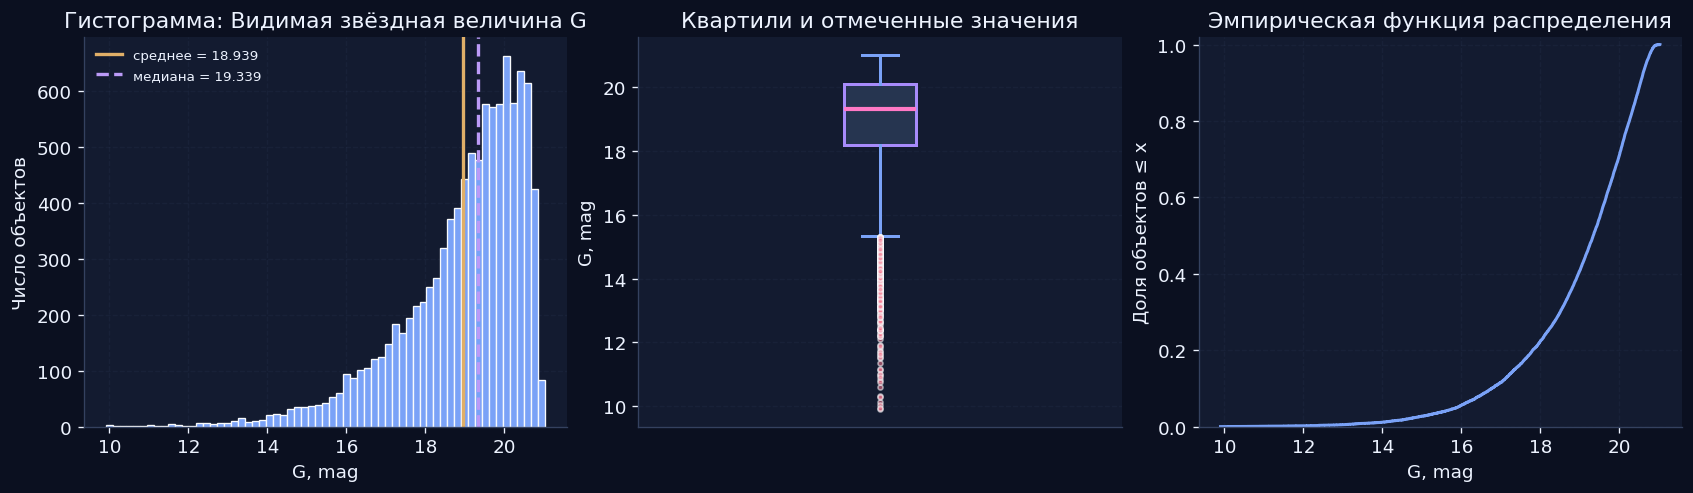

In [ ]:

# @title Описательная статистика: видимая звёздная величина G

from IPython.display import display, HTML
from html import escape

info = FEATURES[0]
a = df[info['column']].to_numpy(float)

summary_G, flags_G = describe_feature(a, info['unit'], info['label'])
summary_G.to_csv(OUT / 'G_summary.csv', index=False)


# Описательная статистика
display(
    summary_G.style
    .format(precision=3)
    .set_caption('Описательная статистика: видимая звёздная величина G')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '15px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('color', '#F8FAFC'),
                ('background-color', '#111827'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('text-align', 'left'),
                ('padding', '10px'),
                ('border-bottom', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd) td',
            'props': [
                ('background-color', '#F5F3FF')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(even) td',
            'props': [
                ('background-color', '#FFFFFF')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('border', '1px solid #D8D4F0'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px')
            ]
        }
    ])
    .hide(axis='index')
)


# Графики
plot_eda(a, info, 'G')


# Оформленный вывод
display(HTML(f"""
<div style="
    font-family:Arial,sans-serif;
    margin:20px 0;
    border:1px solid #D8D4F0;
    border-radius:10px;
    overflow:hidden;
    color:#1F2937;
">
    <div style="
        background:#111827;
        color:#F8FAFC;
        padding:14px 18px;
        font-size:16px;
        font-weight:bold;
    ">
        Вывод по звёздной величине G
    </div>

    <div style="
        background:#F5F3FF;
        padding:16px 18px;
        font-size:14px;
        line-height:1.7;
    ">
        <div style="margin-bottom:10px;">
            <b>Среднее:</b> {a.mean():.4f} mag
            <span style="color:#9CA3AF;"> · </span>
            <b>Медиана:</b> {np.median(a):.4f} mag
        </div>

        <div style="margin-bottom:10px;">
            Медиана выше среднего. Это согласуется с наличием хвоста
            распределения в сторону меньших значений G — более ярких объектов.
        </div>

        <div>
            <b>Выбросы по правилу 1.5 IQR:</b> {int(flags_G.sum())}.
            Эти наблюдения не удаляются: среди них могут быть реальные яркие объекты.
        </div>
    </div>
</div>
"""))


### Нормализация G

Для сравнения признаков с разными единицами используем два преобразования:

$$
u=\frac{G-G_{\min}}{G_{\max}-G_{\min}},
\qquad
z=\frac{G-\bar G}{s}.
$$

После min–max все значения лежат от 0 до 1. После стандартизации среднее равно 0, а исправленное стандартное отклонение равно 1. Эти преобразования меняют шкалу, но не делают распределение нормальным автоматически.


Показатель,Значение
min–max min,0.00000000
min–max max,1.00000000
Z среднее,-0.00000000
Z s (N−1),1.00000000


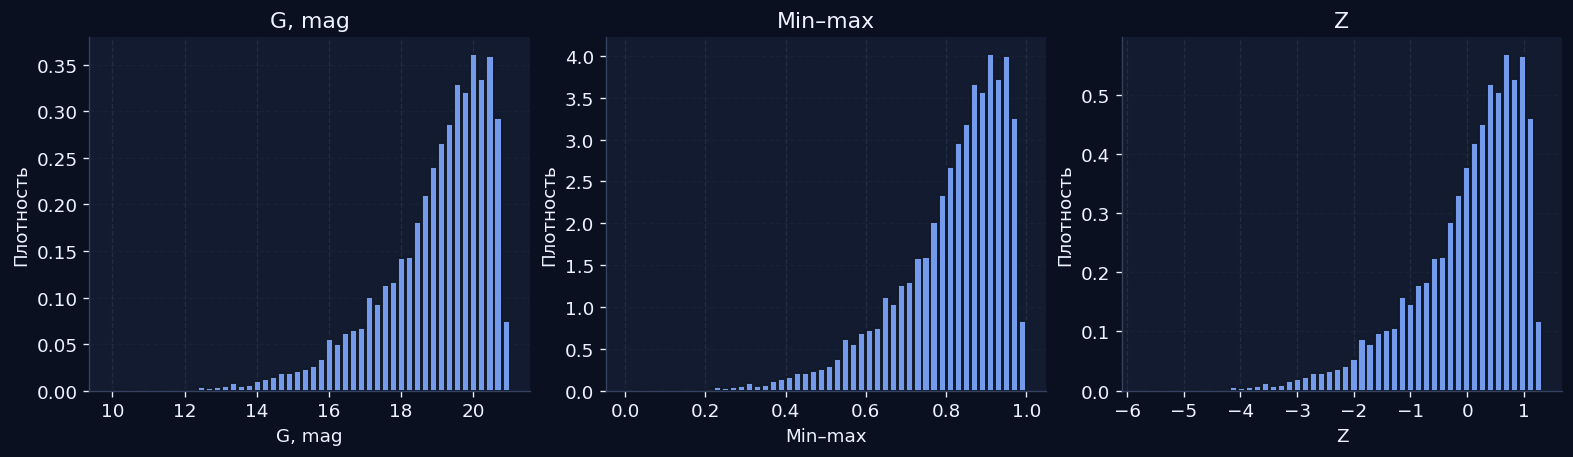

In [ ]:
# @title

def scale_feature(values, info, prefix):
    a = np.asarray(values, float)
    u = (a - a.min()) / (a.max() - a.min())
    z = (a - a.mean()) / a.std(ddof=1)

    result = pd.DataFrame({
        'Исходное': a,
        'Min–max': u,
        'Z': z
    })
    result.to_csv(OUT/(prefix+'_scaled.csv'), index=False)

    check = pd.DataFrame({
        'Показатель': ['min–max min', 'min–max max', 'Z среднее', 'Z s (N−1)'],
        'Значение': [u.min(), u.max(), z.mean(), z.std(ddof=1)]
    })

    display(
        check.round(8).style
        .format(precision=8)
        .set_caption('Проверка масштабирования')
        .set_table_styles([
            {'selector': 'caption', 'props': [
                ('caption-side', 'top'),
                ('font-size', '15px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('color', '#F8FAFC'),
                ('background-color', '#111827'),
                ('padding', '12px'),
                ('border-radius', '8px 8px 0 0')
            ]},
            {'selector': 'th', 'props': [
                ('background-color', '#1E293B'),
                ('color', '#F8FAFC'),
                ('text-align', 'left'),
                ('padding', '10px'),
                ('border-bottom', '2px solid #A78BFA')
            ]},
            {'selector': 'td', 'props': [
                ('background-color', '#F5F3FF'),
                ('color', '#1F2937'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #D8D4F0')
            ]},
            {'selector': 'table', 'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('border', '1px solid #D8D4F0'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '12px')
            ]}
        ])
        .hide(axis='index')
    )

    assert np.isclose(u.min(), 0) and np.isclose(u.max(), 1)
    assert np.isclose(z.mean(), 0, atol=1e-12)
    assert np.isclose(z.std(ddof=1), 1)

    fig, ax = plt.subplots(
        1, 3, figsize=(13, 3.7), constrained_layout=True
    )

    plot_data = [
        (a, f"{info['label']}, {info['unit']}"),
        (u, 'Min–max'),
        (z, 'Z')
    ]

    for axis, (v, label) in zip(ax, plot_data):
        axis.hist(
    v,
    bins=50,
    color=info['color'],
    edgecolor='#111827',
    linewidth=1.2,
    rwidth=0.88,
    density=True,
    alpha=0.95
)
        axis.set(
            xlabel=label,
            ylabel='Плотность',
            title=label
        )
        axis.grid(axis='y', alpha=0.18, linestyle='--')
        axis.set_axisbelow(True)

    fig.savefig(
        OUT/(prefix+'_scaling.png'),
        bbox_inches='tight'
    )
    plt.show()

    return result


scaled_G = scale_feature(a, info, 'G')


### Математическая модель распределения G

Мы сравниваем три модели, чтобы проверить, насколько простое распределение может описать наши данные. Нормальная модель симметрична, распределение Лапласа имеет более выраженный центральный пик и тяжёлые хвосты, а асимметричная нормальная модель допускает скошенность.

Код случайно разделяет 10 000 значений на две части: по 7000 оценивает параметры моделей, а по оставшимся 3000 проверяет согласие с данными. Так мы проверяем модель на значениях, которые не использовались для её подгонки.

AIC и BIC рассчитываются по обучающей части. Они позволяют сравнить качество подгонки с учётом числа параметров: меньшие значения предпочтительнее среди рассматриваемых моделей. Однако даже лучшая из трёх моделей может плохо описывать данные.

Критерий Колмогорова - Смирнова сравнивает эмпирическую функцию распределения контрольных данных с функцией распределения подогнанной модели. Чем больше статистика D, тем сильнее максимальное расхождение между ними. Для трёх проверок применяется поправка Холма.

При p_Holm < 0,05 отвергаем гипотезу о соответствии проверяемой модели. При p_Holm ≥ 0,05 оснований отвергать её недостаточно. Это не доказывает правильность модели. Уровень значимости 0,05 задаёт допустимый риск ошибочного отвержения верной гипотезы при выполнении условий проверки.

Разделение данных устраняет прямую подгонку параметров по контрольным значениям. При этом результаты проверки рассматриваем как приближённые: реальные наблюдения и конечная рабочая база могут отличаться от идеальных условий статистического критерия.




Параметры моделей приведены отдельно. loc задаёт положение распределения, scale — его масштаб, а shape — форму асимметричной нормальной модели. У нормального распределения loc совпадает со средним, а scale — со стандартным отклонением. Для распределения Лапласа scale не равен стандартному отклонению. У асимметричной нормальной модели loc и scale также нельзя автоматически считать средним и стандартным отклонением.

Модель,"Обучение, n","Контроль, n",Параметров,AIC,BIC,KS D на контроле,p на контроле,Средний log-loss,p_Holm,"Решение при α=0,05"
Лапласа,7000,3000,2,15568.395,15582.102,0.05120,2.838e-07,1.14538,2.838e-07,Отвергаем H₀
Асимметричная нормальная,7000,3000,3,19053.128,19073.689,0.12277,7.197e-40,1.36310,1.439e-39,Отвергаем H₀
Нормальная,7000,3000,2,19205.292,19219.000,0.12704,1.142e-42,1.36754,3.426e-42,Отвергаем H₀


Модель,loc,scale,shape
Нормальная,0.37244,0.95369,—
Лапласа,0.31184,0.55911,—
Асимметричная нормальная,-0.27913,1.15501,1.03834


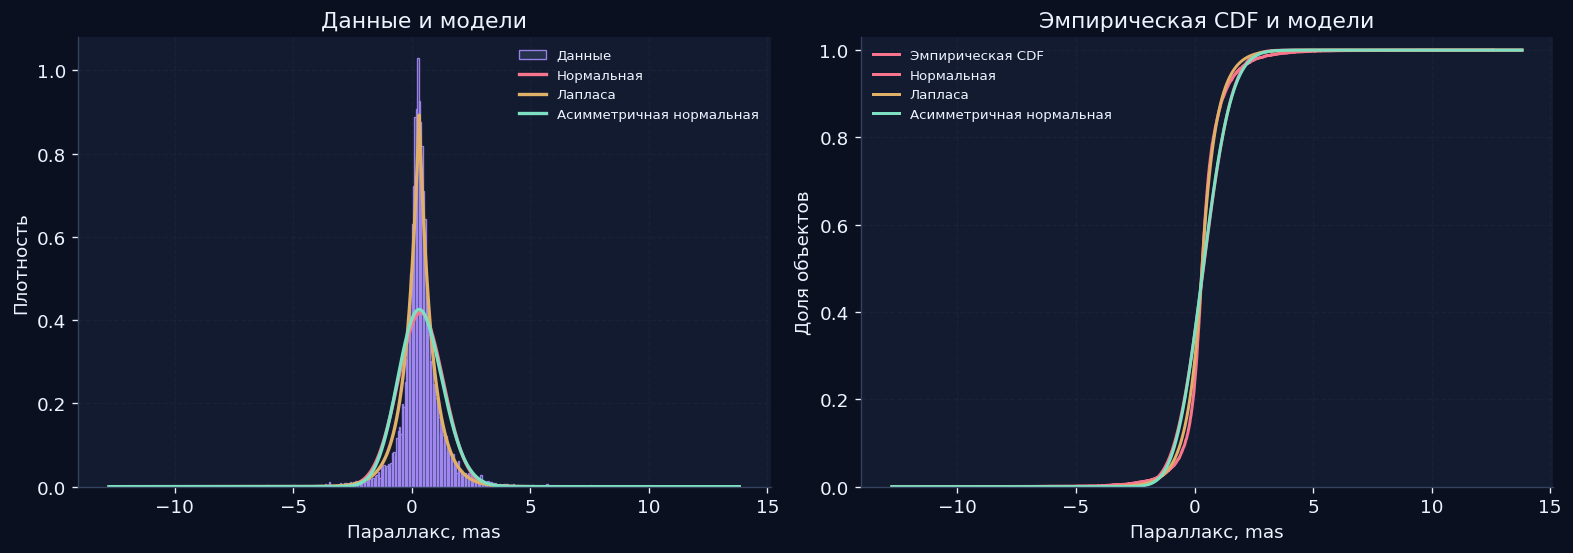

In [ ]:

# @title Модели распределения звёздной величины G

models_G, fitted_G, train_G, test_G = fit_models_train_test(a, 'G')
models_G.to_csv(OUT / 'G_distribution_models.csv', index=False)


# Таблица сравнения моделей
display(
    models_G.style.format({
    'AIC': '{:.3f}',
    'BIC': '{:.3f}',
    'KS D на контроле': '{:.5f}',
    'p на контроле': '{:.3e}',
    'p_Holm': '{:.3e}',
    'Средний log-loss': '{:.5f}'
})
    .set_caption('Сравнение моделей распределения звёздной величины G')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '15px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('color', '#F8FAFC'),
                ('background-color', '#111827'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('text-align', 'left'),
                ('padding', '10px'),
                ('border-bottom', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd) td',
            'props': [
                ('background-color', '#F5F3FF')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(even) td',
            'props': [
                ('background-color', '#FFFFFF')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('border', '1px solid #D8D4F0'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px')
            ]
        }
    ])
    .hide(axis='index')
)


# Графики моделей
parameter_rows = []
for name, (_, params) in fitted_G.items():
    names = (
        ['shape', 'loc', 'scale']
        if len(params) == 3 else ['loc', 'scale']
    )
    parameter_rows.append({
        'Модель': name,
        **dict(zip(names, params))
    })

display(
    pd.DataFrame(parameter_rows).style
    .format(precision=5, na_rep='—')
    .hide(axis='index')
)
plot_models(a, info, models_G, fitted_G, 'G')


# Итоговый вывод
display(HTML("""
<div style="
    font-family:Arial,sans-serif;
    margin:20px 0;
    border:1px solid #D8D4F0;
    border-radius:10px;
    overflow:hidden;
    color:#1F2937;
">
    <div style="
        background:#111827;
        color:#F8FAFC;
        padding:14px 18px;
        font-size:16px;
        font-weight:bold;
    ">
        Вывод по моделям распределения G
    </div>
    <div style="
        background:#F5F3FF;
        padding:16px 18px;
        font-size:14px;
        line-height:1.7;
    ">
        Среди трёх проверенных моделей наименьший BIC получила асимметричная нормальная модель: примерно 23 285,6. Однако при уровне значимости 0,05 все три модели отвергаются по контрольным данным после поправки Холма. Поэтому преимущество по BIC ещё не означает, что модель достаточно хорошо описывает распределение G. Для воспроизведения значений нашей рабочей базы используем эмпирическое распределение.
    </div>
</div>
"""))


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
4. Случайная величина 02 — цвет BP − RP (участник 2)
</h2></div>
"""))

<a id="rv02"></a>
### Что означает цвет

`BP − RP` — разность измерений в синем и красном фотометрических каналах Gaia. Большие значения обычно соответствуют более красному наблюдаемому свету. Цвет зависит от спектра объекта, межзвёздного поглощения и качества измерения. По одному цвету нельзя точно восстановить температуру или химический состав звезды.

Случайной величиной считается цвет объекта, выбранного случайно из общей базы. Наблюдаемая конечная база задаёт дискретное эмпирическое распределение: одинаковые значения получают суммарную вероятность.


### Как цвет связан со спектром и химическим составом

BP − RP характеризует соотношение света в двух широких фотометрических каналах. Спектр содержит более подробную информацию: он показывает, как поток излучения меняется с длиной волны. Разные спектры могут давать близкий показатель цвета, поэтому по одному BP − RP нельзя однозначно определить химический состав.

Атомы и ионы поглощают свет при переходах между определёнными энергетическими уровнями. На спектре появляются линии поглощения. Их положения и сочетания сопоставляют с известными переходами элементов. Содержание элементов оценивают с помощью моделей атмосферы, учитывающих температуру, давление, ионизацию и уширение линий. Поэтому глубина одной линии сама по себе ещё не показывает количество элемента.

### Пример: зелёный оттенок белого карлика

В работе Hollands и соавторов (2026) исследован цвет белого карлика WD J1330+6435. Этот объект был известен ранее; новая работа рассматривает его воспринимаемый цвет по спектру.

В его атмосфере обнаружены литий, натрий и кальций. Зелёный оттенок авторы связывают с широким поглощением натрия в оранжевой области и кальция в фиолетовой. В результате относительно сильнее остаётся свет около 500 нм. Следовательно, необычный цвет возникает из-за изменения формы спектра поглощением, а не из-за того, что литий «светится зелёным».

Этот пример показывает, почему цвет зависит не только от температуры. При этом он служит иллюстрацией из литературы: мы не проверяли, входит ли этот белый карлик в наши 10 000 объектов, и не определяли состав объектов нашей базы по BP − RP. [12]

![Спектры белых карликов из рисунка 16](https://arxiv.org/html/2610.18966v1/DZ2.png)

**Рисунок.** Наблюдаемые спектры и модели белых карликов из
рисунка 16 работы Hollands et al. (2026). WD J1330+6435 показан
на верхней правой панели. По горизонтали отложена длина волны
в ангстремах, по вертикали — спектральный поток.
Это опубликованный рисунок авторов, а не результат нашего расчёта. [14]

Показатель,Значение,Единицы
Число объектов,10000.000000,объектов
Среднее,1.620746,mag
Медиана,1.530344,mag
Дисперсия базы (N),0.372466,mag²
Исправленная дисперсия,0.372503,mag²
Стандартное отклонение,0.610331,mag
Минимум,-1.119076,mag
Q1,1.190716,mag
Q3,1.952171,mag
Максимум,7.030882,mag


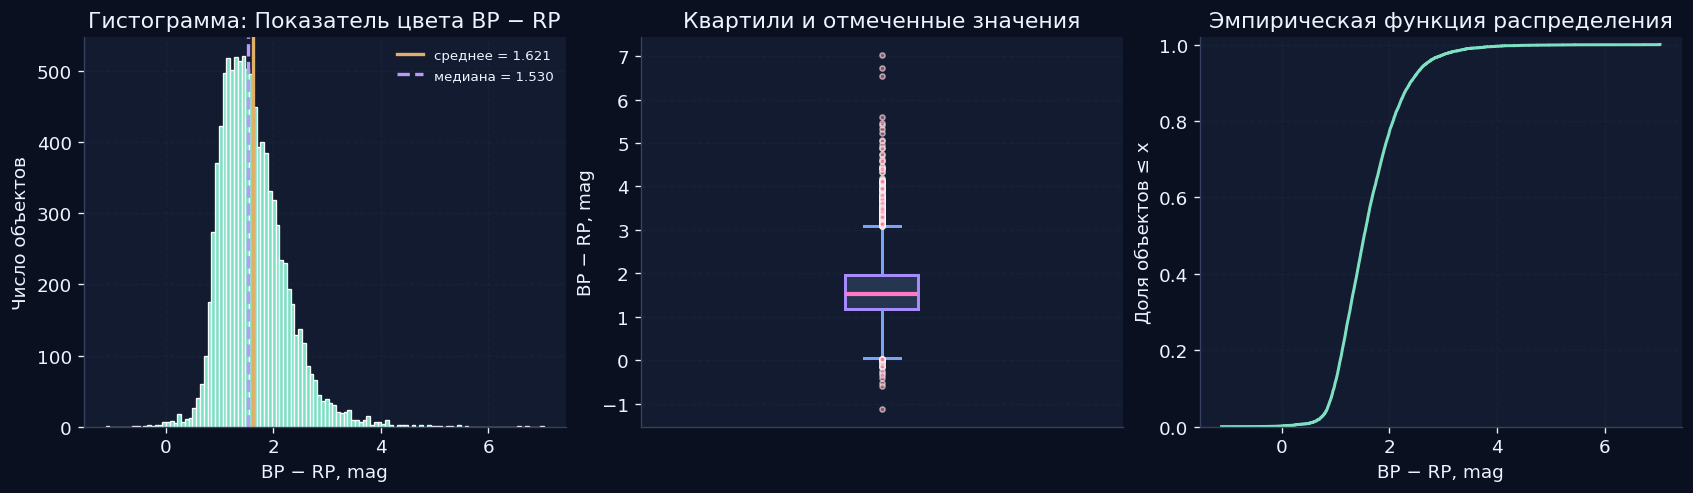

Показатель,Значение
min–max min,0.00000000
min–max max,1.00000000
Z среднее,-0.00000000
Z s (N−1),1.00000000


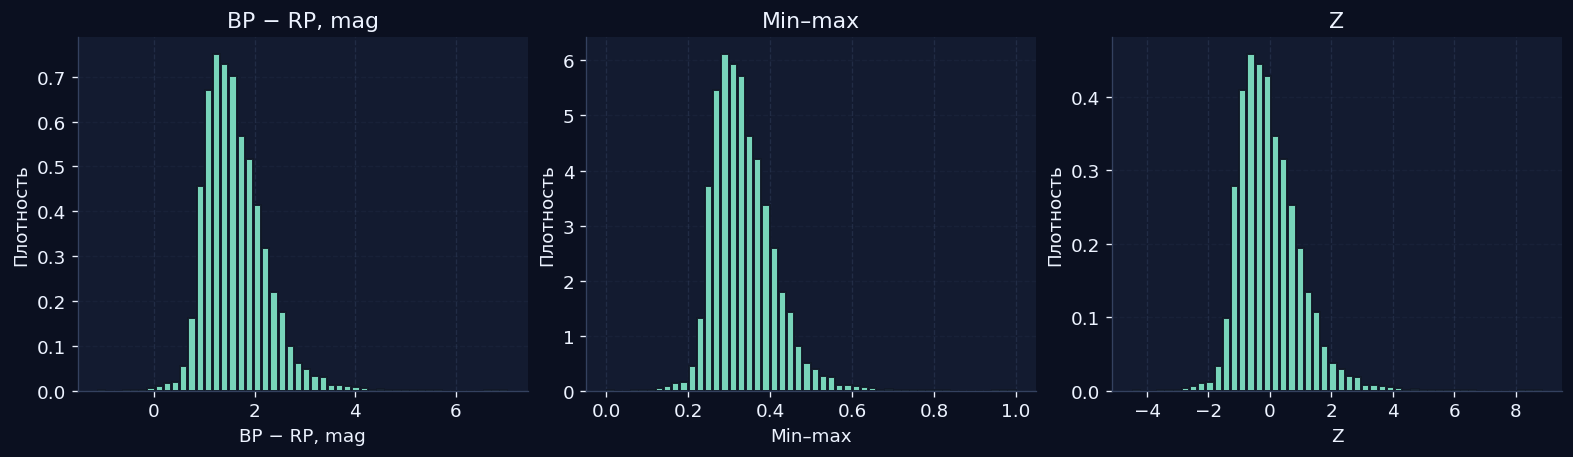

In [ ]:

# @title Описательная статистика: цвет BP-RP

from IPython.display import display, HTML

info = FEATURES[1]
a = df[info['column']].to_numpy(float)

summary_color, flags_color = describe_feature(
    a, info['unit'], info['label']
)
summary_color.to_csv(OUT / 'BP_RP_summary.csv', index=False)


# Таблица описательной статистики
display(
    summary_color.round(6).style
    .set_caption('Описательная статистика: цвет BP-RP')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '15px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('color', '#F8FAFC'),
                ('background-color', '#111827'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('text-align', 'left'),
                ('padding', '10px'),
                ('border-bottom', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd) td',
            'props': [
                ('background-color', '#F5F3FF')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(even) td',
            'props': [
                ('background-color', '#FFFFFF')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'collapse'),
                ('width', '100%'),
                ('border', '1px solid #D8D4F0'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px')
            ]
        }
    ])
    .hide(axis='index')
)


# Графики
plot_eda(a, info, 'BP_RP')


# Итоговый вывод
display(HTML(f"""
<div style="
    font-family:Arial,sans-serif;
    margin:20px 0;
    border:1px solid #D8D4F0;
    border-radius:10px;
    overflow:hidden;
    color:#1F2937;
">
    <div style="
        background:#111827;
        color:#F8FAFC;
        padding:14px 18px;
        font-size:16px;
        font-weight:bold;
    ">
        Вывод по цвету BP-RP
    </div>

    <div style="
        background:#F5F3FF;
        padding:16px 18px;
        font-size:14px;
        line-height:1.7;
    ">
        <div style="margin-bottom:10px;">
            <b>Среднее:</b> {a.mean():.4f} mag
            <span style="color:#9CA3AF;"> · </span>
            <b>Медиана:</b> {np.median(a):.4f} mag
        </div>

        <div>
            <b>Выбросы по правилу 1.5 IQR:</b> {int(flags_color.sum())}.
            Отмеченные значения не удаляются автоматически:
            сначала нужно определить, являются ли они ошибками
            или редкими объектами.
        </div>
    </div>
</div>
"""))


# Масштабирование признака для дальнейшего анализа
scaled_color = scale_feature(a, info, 'BP_RP')


### Математическая модель цвета

Для цвета проверяются те же три семейства. Дополнительно в работе сохраняется эмпирическое распределение как точная модель конечной базы. Если все непрерывные модели отвергаются, это означает, что они плохо описывают именно наблюдаемую рабочую базу; это не означает, что данные «не имеют распределения».


Модель,"Обучение, n","Контроль, n",Параметров,AIC,BIC,KS D на контроле,p на контроле,Средний log-loss,p_Holm,"Решение при α=0,05"
Лапласа,7000,3000,2,15541.259,15554.967,0.05364,6.083e-08,1.15011,6.083e-08,Отвергаем H₀
Асимметричная нормальная,7000,3000,3,18547.062,18567.623,0.12544,1.316e-41,1.45248,2.632e-41,Отвергаем H₀
Нормальная,7000,3000,2,18689.121,18702.828,0.13184,6.292e-46,1.45792,1.888e-45,Отвергаем H₀


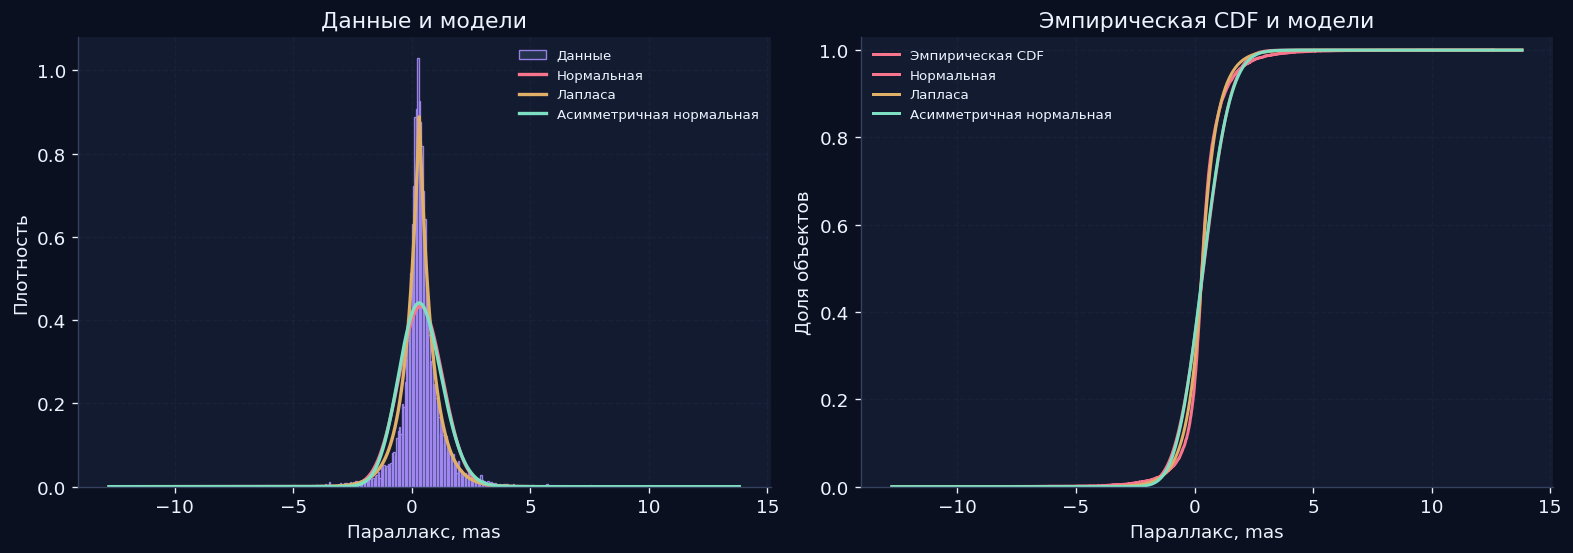

Модель,loc,scale,shape
Нормальная,0.37480,0.91917,—
Лапласа,0.31761,0.55803,—
Асимметричная нормальная,-0.26381,1.11923,1.05808


In [ ]:
# @title Модели распределения цвета BP-RP

from IPython.display import display, HTML

models_color, fitted_color, train_color, test_color = fit_models_train_test(
    a, 'BP−RP'
)

models_color.to_csv(
    OUT / 'BP_RP_distribution_models.csv',
    index=False
)

display(
    models_color.style.format({
    'AIC': '{:.3f}',
    'BIC': '{:.3f}',
    'KS D на контроле': '{:.5f}',
    'p на контроле': '{:.3e}',
    'p_Holm': '{:.3e}',
    'Средний log-loss': '{:.5f}'
})
    .set_caption('Сравнение моделей распределения цвета BP-RP')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

plot_models(a, info, models_color, fitted_color, 'BP_RP')
parameter_rows = []
for name, (_, params) in fitted_color.items():
    names = (
        ['shape', 'loc', 'scale']
        if len(params) == 3 else ['loc', 'scale']
    )
    parameter_rows.append({
        'Модель': name,
        **dict(zip(names, params))
    })

display(
    pd.DataFrame(parameter_rows).style
    .format(precision=5, na_rep='—')
    .hide(axis='index')
)

display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    margin-top: 12px;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 12px;
        font-weight: bold;
    ">
        Вывод по распределению цвета BP-RP
    </div>
    <div style="
        background: #F5F3FF;
        padding: 14px;
        line-height: 1.6;
    ">
        Для цвета лучший BIC получила асимметричная нормальная модель: примерно 12 159,0. После поправки Холма её p-value составляет 0,131, что больше 0,05. Поэтому оснований отвергать эту модель в проведённой проверке недостаточно. Нормальная модель и распределение Лапласа отвергаются. Асимметричную нормальную модель можно использовать как приближённое описание цвета, но её истинность этим не доказана. Для генератора по конечной базе сохраняем эмпирическое распределение.
    </div>
</div>
"""))

[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
5. Случайная величина 03 — измеренный параллакс
</h2></div>
"""))

<a id="rv03"></a>
### Что означает параллакс

Параллакс — видимое годовое угловое смещение объекта, возникающее из-за движения Земли вокруг Солнца. Его используют для оценки расстояния, но в этой работе анализируется именно **измеренный параллакс**, а не величина (1/\pi). При малом сигнале ошибка измерения может быть сравнима с самим значением, поэтому отрицательные измерения сохраняются и рассматриваются как часть наблюдаемой статистики.

Случайной величиной считаем параллакс объекта, равновероятно выбранного из рабочей базы. Пока объект не выбран, мы не знаем, какое значение получим. После выбора его измеренный параллакс известен из таблицы. Различия расстояний и ошибки измерений влияют на распределение значений, которое мы наблюдаем.

Показатель,Значение,Единицы
Число объектов,10000.000000,объектов
Среднее,0.371944,mas
Медиана,0.312884,mas
Дисперсия базы (N),0.907350,mas²
Исправленная дисперсия,0.907441,mas²
Стандартное отклонение,0.952597,mas
Минимум,-11.552422,mas
Q1,0.024495,mas
Q3,0.662262,mas
Максимум,12.599344,mas


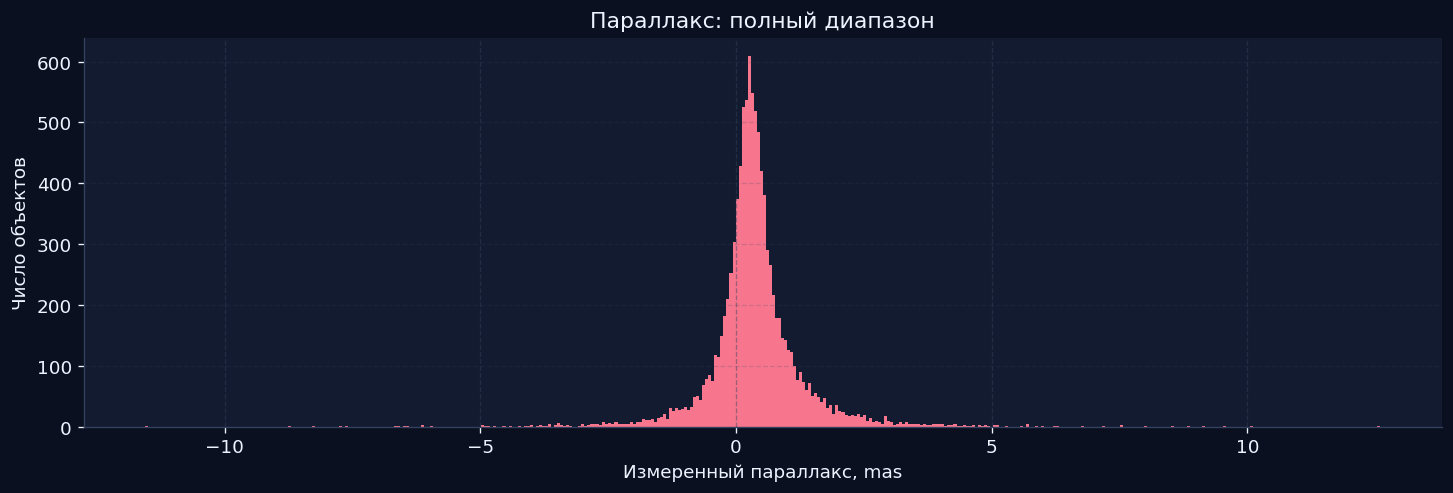

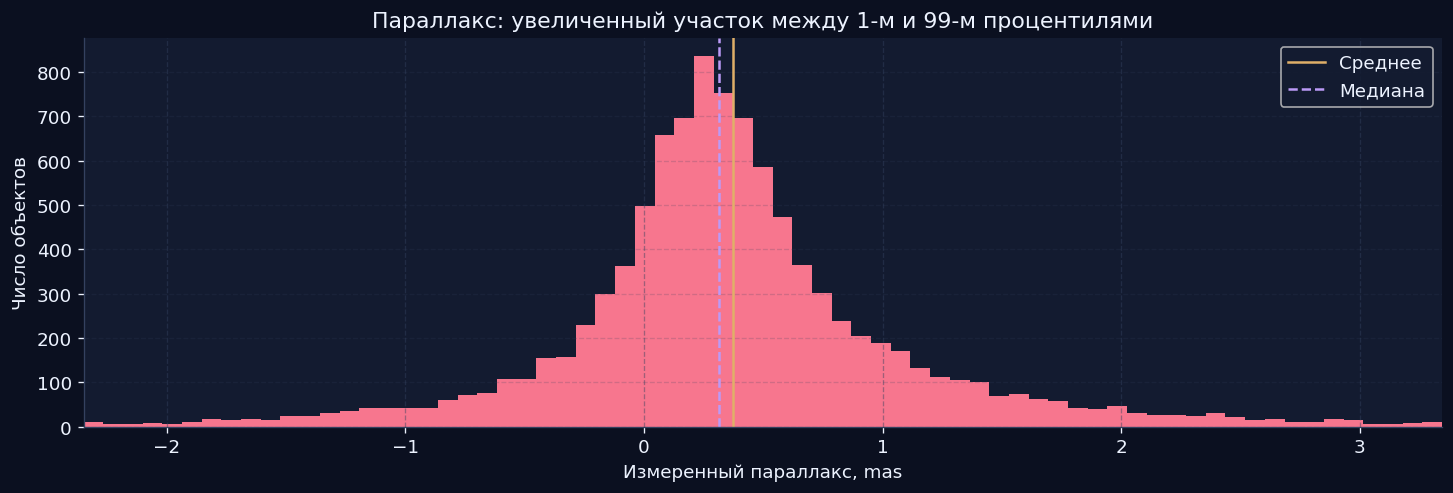

Показатель,Значение
min–max min,0.00000000
min–max max,1.00000000
Z среднее,0.00000000
Z s (N−1),1.00000000


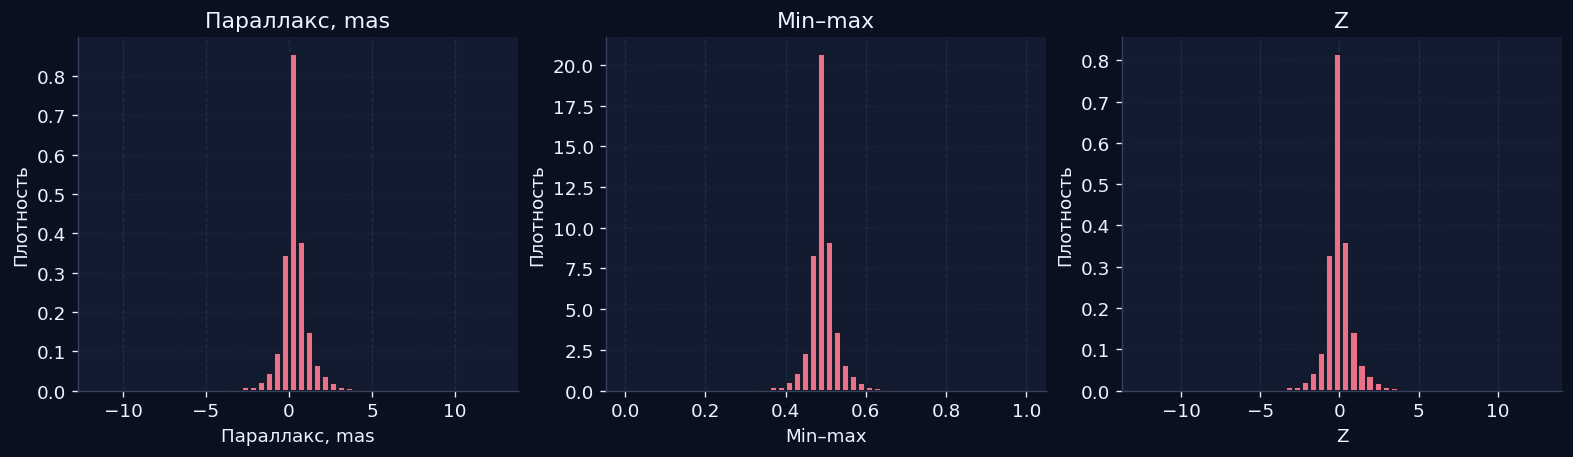

In [ ]:
# @title Описательная статистика: параллакс

from IPython.display import display, HTML

info = FEATURES[2]
a = df[info['column']].to_numpy(float)

summary_parallax, flags_parallax = describe_feature(
    a, info['unit'], info['label']
)
summary_parallax.to_csv(OUT / 'parallax_summary.csv', index=False)

display(
    summary_parallax.round(6).style
    .set_caption('Описательная статистика: параллакс')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

# Полный диапазон сохраняем, чтобы были видны хвосты.
fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.hist(a, bins='fd', color=info['color'])
ax.set(
    xlabel='Измеренный параллакс, mas',
    ylabel='Число объектов',
    title='Параллакс: полный диапазон'
)
ax.grid(axis='y', alpha=.2)
fig.savefig(OUT / 'parallax_hist_full.png', bbox_inches='tight')
plt.show()

# Отдельно увеличиваем центральные 98% наблюдений.
lo, hi = np.quantile(a, [.01, .99])
edges = np.linspace(lo, hi, 70)

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.hist(a, bins=edges, color=info['color'])
ax.axvline(a.mean(), color=COLORS['mean'], label='Среднее')
ax.axvline(
    np.median(a), color=COLORS['median'],
    linestyle='--', label='Медиана'
)
ax.set(
    xlim=(lo, hi),
    xlabel='Измеренный параллакс, mas',
    ylabel='Число объектов',
    title='Параллакс: увеличенный участок между 1-м и 99-м процентилями'
)
ax.legend()
ax.grid(axis='y', alpha=.2)
fig.savefig(OUT / 'parallax_hist_center.png', bbox_inches='tight')
plt.show()

display(HTML(f"""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    margin-top: 12px;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 12px;
        font-weight: bold;
    ">
        Вывод по параллаксу
    </div>
    <div style="
        background: #F5F3FF;
        padding: 14px;
        line-height: 1.6;
    ">
        <b>Средний измеренный параллакс:</b> {a.mean():.4f} mas<br>
        <b>Медиана:</b> {np.median(a):.4f} mas<br>
        <b>Отрицательные измерения:</b> {int((a < 0).sum())}.
        Они не удаляются, поскольку это результат измерения с ошибкой,
        а не физическое отрицательное расстояние.
    </div>
</div>
"""))

scaled_parallax = scale_feature(a, info, 'parallax')

### Математическая модель параллакса

Параметрические распределения сравниваются на контрольной части данных. Из-за ошибок измерения и наблюдательного отбора форма параллакса может отличаться от простого симметричного колокола. Поэтому для практического генератора снова оставляем возможность использовать точную эмпирическую CDF рабочей базы.


Модель,"Обучение, n","Контроль, n",Параметров,AIC,BIC,KS D на контроле,p на контроле,Средний log-loss,p_Holm,"Решение при α=0,05"
Лапласа,7000,3000,2,15824.872,15838.580,0.07587,1.830e-15,1.10258,1.830e-15,Отвергаем H₀
Асимметричная нормальная,7000,3000,3,19131.301,19151.862,0.14547,7.183e-56,1.35080,1.437e-55,Отвергаем H₀
Нормальная,7000,3000,2,19308.240,19321.948,0.14683,6.501e-57,1.35065,1.950e-56,Отвергаем H₀


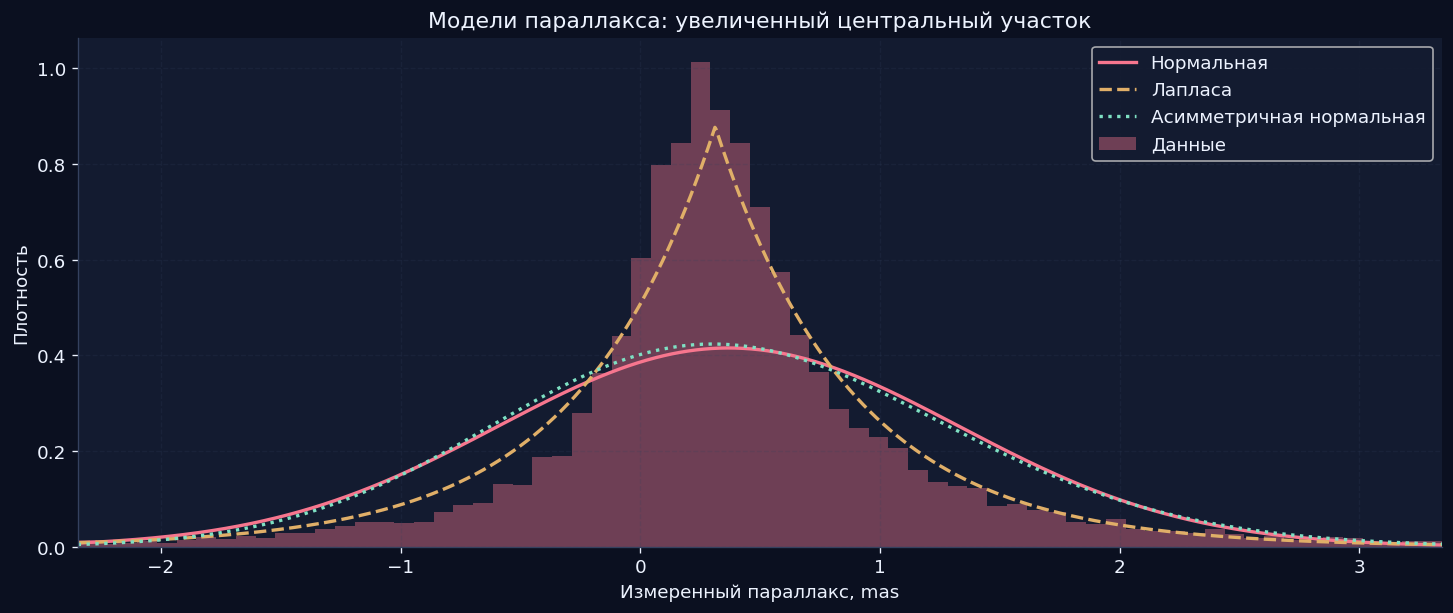

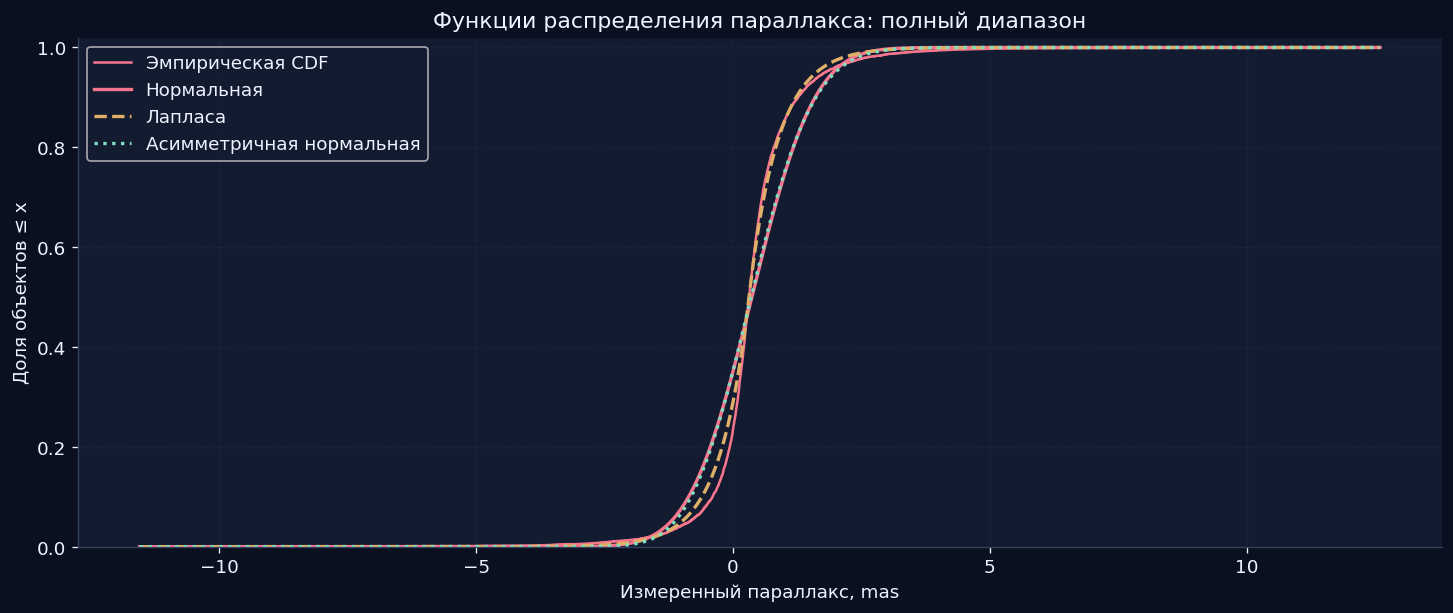

Модель,loc,scale,shape
Нормальная,0.36759,0.96073,—
Лапласа,0.31187,0.56945,—
Асимметричная нормальная,-0.30717,1.17399,1.08273


In [ ]:
# @title Модели распределения параллакса

from IPython.display import display, HTML

models_parallax, fitted_parallax, train_parallax, test_parallax = fit_models_train_test(
    a, 'Параллакс'
)

models_parallax.to_csv(
    OUT / 'parallax_distribution_models.csv',
    index=False
)

display(
    models_parallax.style.format({
    'AIC': '{:.3f}',
    'BIC': '{:.3f}',
    'KS D на контроле': '{:.5f}',
    'p на контроле': '{:.3e}',
    'p_Holm': '{:.3e}',
    'Средний log-loss': '{:.5f}'
})
    .set_caption('Сравнение моделей распределения параллакса')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

lo, hi = np.quantile(a, [.01, .99])
grid = np.linspace(lo, hi, 1200)
edges = np.linspace(lo, hi, 70)

# Делим на полное число наблюдений:
# значения вне показанного участка сохраняют свою вероятность.
counts, _ = np.histogram(a, bins=edges)
density = counts / (len(a) * np.diff(edges))

colors = ['#F7768E', '#E0AF68', '#7EE0C3']
styles = ['-', '--', ':']

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
ax.bar(
    edges[:-1], density, width=np.diff(edges),
    align='edge', color=info['color'], alpha=.4,
    label='Данные'
)

for (name, (dist, params)), color, style in zip(
    fitted_parallax.items(), colors, styles
):
    ax.plot(
        grid, dist.pdf(grid, *params),
        color=color, linestyle=style, linewidth=2, label=name
    )

ax.set(
    xlim=(lo, hi),
    xlabel='Измеренный параллакс, mas',
    ylabel='Плотность',
    title='Модели параллакса: увеличенный центральный участок'
)
ax.legend()
ax.grid(alpha=.2)
fig.savefig(OUT / 'parallax_models_density.png', bbox_inches='tight')
plt.show()

# Функцию распределения показываем отдельно в полном диапазоне.
grid_full = np.linspace(a.min(), a.max(), 3000)
ordered = np.sort(a)

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
ax.step(
    ordered, np.arange(1, len(a) + 1) / len(a),
    where='post', color=info['color'], label='Эмпирическая CDF'
)

for (name, (dist, params)), color, style in zip(
    fitted_parallax.items(), colors, styles
):
    ax.plot(
        grid_full, dist.cdf(grid_full, *params),
        color=color, linestyle=style, linewidth=2, label=name
    )

ax.set(
    xlabel='Измеренный параллакс, mas',
    ylabel='Доля объектов ≤ x',
    ylim=(0, 1.02),
    title='Функции распределения параллакса: полный диапазон'
)
ax.legend()
ax.grid(alpha=.2)
fig.savefig(OUT / 'parallax_models_cdf.png', bbox_inches='tight')
plt.show()
parameter_rows = []
for name, (_, params) in fitted_parallax.items():
    names = (
        ['shape', 'loc', 'scale']
        if len(params) == 3 else ['loc', 'scale']
    )
    parameter_rows.append({
        'Модель': name,
        **dict(zip(names, params))
    })

display(
    pd.DataFrame(parameter_rows).style
    .format(precision=5, na_rep='—')
    .hide(axis='index')
)

display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    margin-top: 12px;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 12px;
        font-weight: bold;
    ">
        Вывод по распределению параллакса
    </div>
    <div style="
        background: #F5F3FF;
        padding: 14px;
        line-height: 1.6;
    ">
        Для параллакса наименьший BIC получило распределение Лапласа: примерно 15 838,6. Однако все три проверенные модели отвергаются при уровне значимости 0,05 после поправки Холма. Следовательно, распределение Лапласа оказалось лучшим среди рассмотренных вариантов, но этого недостаточно для признания его подходящей моделью. Для генерации измеренных параллаксов используем эмпирическое распределение, сохраняя отрицательные значения. Они относятся к результатам измерения с ошибкой и не означают отрицательного расстояния.
    </div>
</div>
"""))

[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
6. Зависимость между тремя величинами
</h2></div>
"""))

<a id="dependence"></a>

Проверяем три пары: G и BP − RP, G и параллакс, BP − RP и параллакс. Хотим понять, меняется ли одна характеристика вместе с другой.

**Коэффициент Пирсона** измеряет линейную связь:

$$
r=
\frac{\sum_{i=1}^{N}(x_i-\bar x)(y_i-\bar y)}
{\sqrt{\sum_{i=1}^{N}(x_i-\bar x)^2
\sum_{i=1}^{N}(y_i-\bar y)^2}}.
$$

Положительный знак означает, что большие значения одной величины обычно сопровождаются большими значениями другой. Отрицательный знак показывает обратное направление. Значения ближе к −1 или 1 соответствуют более выраженной линейной связи.

**Коэффициент Спирмена** рассчитывается по рангам: вместо самих чисел используются их места в упорядоченном списке. Одинаковым значениям присваиваются средние ранги. Поэтому он оценивает монотонную связь, которая может быть нелинейной:

$$
\rho=r(R_x,R_y).
$$

Для проверки используем нулевую гипотезу: две характеристики независимы. Код 1999 раз перемешивает ранги второй характеристики и каждый раз заново считает корреляцию. При этом значения каждого столбца сохраняются, но исходные соответствия между объектами разрушаются [6, 7].

Считаем, сколько перемешиваний дали коэффициент по модулю не меньше наблюдаемого. Если таких случаев $b$, то

$$
p_{\mathrm{perm}}=\frac{b+1}{1999+1}.
$$

Прибавление единицы учитывает исходный результат и не позволяет получить нулевое p-value при конечном числе перемешиваний.

Мы проверяем сразу три пары, поэтому применяем поправку Холма. Она контролирует риск хотя бы одного ошибочного отвержения верной гипотезы в этой группе проверок. В таблице скорректированные значения `p_Holm` сравниваем с уровнем значимости 0,05 [9].

Нулевой коэффициент не доказывает независимость: связь может иметь более сложную форму. Обнаруженная корреляция также не устанавливает физическую причину.

Пара,Pearson r,Pearson p,Spearman ρ,Spearman p,p перестановочный,p_Holm,Решение
G — BP−RP,0.112891,9.998e-30,0.143834,2.270e-47,5.000e-04,1.500e-03,Независимость отвергается
G — Параллакс,-0.127787,1.117e-37,-0.093355,8.378e-21,5.000e-04,1.500e-03,Независимость отвергается
BP−RP — Параллакс,0.104428,1.185e-25,0.128856,2.749e-38,5.000e-04,1.500e-03,Независимость отвергается


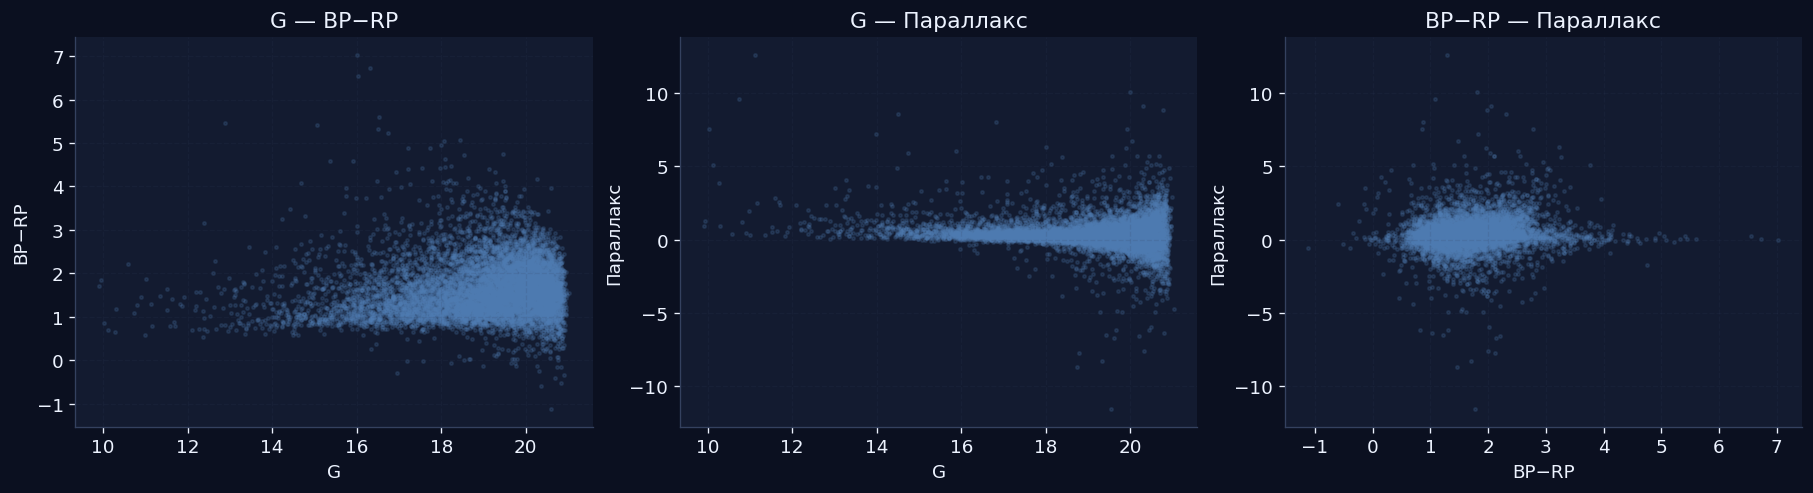

In [ ]:
#@title Анализ зависимости между признаками Gaia DR3

from IPython.display import display, HTML

# Три пары характеристик
pair_specs = [
    ('G', 'BP−RP'),
    ('G', 'Параллакс'),
    ('BP−RP', 'Параллакс')
]

arrays = {
    feature['key']: df[feature['column']].to_numpy(float)
    for feature in FEATURES
}

B_PERM = 1999
pair_rows = []

for pair_index, (left, right) in enumerate(pair_specs):
    x1, x2 = arrays[left], arrays[right]

    pear = stats.pearsonr(x1, x2)
    spear = stats.spearmanr(x1, x2)

    rng = np.random.default_rng(SEED + 2000 + pair_index)
    observed = abs(float(spear.statistic))
    exceed = 0

    # Перемешиваем ранги второй характеристики
    r1 = stats.rankdata(x1)
    r2 = stats.rankdata(x2)

    for _ in range(B_PERM):
        perm = float(
            np.corrcoef(r1, rng.permutation(r2))[0, 1]
        )
        exceed += abs(perm) >= observed

    pair_rows.append({
        'Пара': f'{left} — {right}',
        'Pearson r': pear.statistic,
        'Pearson p': pear.pvalue,
        'Spearman ρ': spear.statistic,
        'Spearman p': spear.pvalue,
        'p перестановочный': (exceed + 1) / (B_PERM + 1)
    })

dependence_table = pd.DataFrame(pair_rows)

dependence_table['p_Holm'] = holm_adjust(
    dependence_table['p перестановочный'].to_numpy()
)

dependence_table['Решение'] = np.where(
    dependence_table['p_Holm'] < ALPHA,
    'Независимость отвергается',
    'Недостаточно оснований отвергнуть независимость'
)

dependence_table.to_csv(
    OUT / 'dependence_all_pairs.csv',
    index=False
)

# Таблица результатов
display(
    dependence_table.style.format({
        'Pearson r': '{:.6f}',
        'Pearson p': '{:.3e}',
        'Spearman ρ': '{:.6f}',
        'Spearman p': '{:.3e}',
        'p перестановочный': '{:.3e}',
        'p_Holm': '{:.3e}'
    })
    .set_caption(
        'Корреляции и тестирование зависимости между признаками'
    )
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center'),
                ('white-space', 'normal')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [
                ('background-color', '#F5F3FF')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [
                ('background-color', '#FFFFFF')
            ]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

# Диаграммы рассеяния
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
    constrained_layout=True
)

for ax, (left, right) in zip(axes, pair_specs):
    ax.scatter(
        arrays[left],
        arrays[right],
        s=4,
        alpha=0.18,
        color='#527fb5',
        rasterized=True
    )

    ax.set(
        xlabel=left,
        ylabel=right,
        title=f'{left} — {right}'
    )

    ax.grid(alpha=0.15)

fig.savefig(
    OUT / 'dependence_all_pairs.png',
    bbox_inches='tight'
)

plt.show()

# Вывод
display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    margin-top: 12px;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 12px;
        font-weight: bold;
    ">
        Вывод по анализу зависимости
    </div>

    <div style="
        background: #F5F3FF;
        padding: 14px;
        line-height: 1.6;
    ">
        Во всех трёх парах получили
        <b>p_Holm = 0.0015 &lt; 0.05</b>,
        поэтому гипотезу независимости отвергаем.
        <br><br>

        При этом коэффициенты Спирмена небольшие:
        <b>0.144</b> для G и цвета,
        <b>−0.093</b> для G и параллакса,
        <b>0.129</b> для цвета и параллакса.
        Значит, обнаруженная монотонная связь
        во всех трёх случаях слабая.
        <br><br>

        Мы увидели, что маленькое p-value
        не означает сильную связь:
        при 10 000 объектах можно обнаружить
        и небольшой эффект.
        Одинаковые перестановочные p-value получились
        потому, что ни одно из 1999 перемешиваний
        не дало столь же большого по модулю коэффициента.
        <br><br>

        Мы нашли слабые связи между характеристиками.
        Расчёт показывает, что они есть,
        но не объясняет, чем они вызваны.
    </div>
</div>
"""))

[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
7. Генеральная совокупность, выборки и состоятельность оценок
</h2></div>
"""))

<a id="sampling"></a>

Для вычислительных экспериментов считаем нашу рабочую базу из $N=10000$ строк конечной генеральной совокупностью. Её среднее и дисперсию можем рассчитать по всем строкам, а затем сравнивать с оценками по меньшим выборкам.

Рассматриваем два способа отбора:

- **с возвращением** — один объект может попасть в выборку несколько раз;
- **без возвращения** — внутри одной выборки повторов нет.

Обозначим среднее всей базы через $\mu_N$, а её дисперсию с делителем $N$ — через $v_N$:

$$
\mu_N=\frac{1}{N}\sum_{i=1}^{N}x_i,
\qquad
v_N=\frac{1}{N}\sum_{i=1}^{N}(x_i-\mu_N)^2.
$$

Теоретическая дисперсия выборочного среднего равна

$$
\operatorname{Var}_{WR}(\bar X_n)=\frac{v_N}{n},
\qquad
\operatorname{Var}_{WOR}(\bar X_n)
=\frac{v_N}{n}\frac{N-n}{N-1}.
$$

Индексы WR и WOR обозначают отбор с возвращением и без возвращения. Формулы согласуются с [8]; здесь они записаны с учётом нашего определения $v_N$ через делитель $N$.

Множитель $(N-n)/(N-1)$ учитывает конечный размер базы. При отборе без возвращения разброс среднего уменьшается, а при $n=N$ мы получаем всю базу и её точное среднее.

Одной выбранной группы недостаточно, чтобы понять, насколько результат меняется от выборки к выборке. Поэтому для каждого размера — 20, 50, 100, 500, 2000, 5000 и 10 000 объектов — повторяем отбор 300 раз. Отдельно рассматриваем оба способа отбора.

После каждого отбора вычисляем среднее и исправленную выборочную дисперсию. Затем сравниваем оценки с известными параметрами рабочей базы.

Смещение показывает, завышена или занижена оценка в среднем по повторениям. RMSE показывает размер ошибки с учётом и смещения, и разброса. Для среднего:

$$
\operatorname{RMSE}(\bar X)=
\sqrt{\frac{1}{R}\sum_{r=1}^{R}
(\bar x_r-\mu_N)^2},
\qquad R=300.
$$

Маленькое смещение ещё не означает, что отдельные выборки дают точные ответы: положительные и отрицательные ошибки могут взаимно компенсироваться. Поэтому рассматриваем и смещение, и RMSE.

Для оценки дисперсии учитываем способ отбора. При возвращении исправленная выборочная дисперсия оценивает $v_N$, а без возвращения — $S_N^2=Nv_N/(N-1)$. Именно с соответствующим значением код сравнивает результат.

Этот эксперимент показывает, как меняется точность оценок внутри нашей рабочей базы. Повторный отбор из тех же 10 000 строк не устраняет ограничения первоначального отбора из Gaia и не доказывает, что база представляет все звёзды.

In [ ]:
# @title Параметры конечной базы по всем трём величинам

from IPython.display import display

values = df[
    ['phot_g_mean_mag', 'bp_rp', 'parallax']
].to_numpy(float)

feature_keys = ['G', 'BP−RP', 'Параллакс']
feature_labels = ['G, mag', 'BP − RP, mag', 'Параллакс, mas']

population_rows = []

for j, key in enumerate(feature_keys):
    a = values[:, j]

    population_rows.append({
        'Характеристика': feature_labels[j],
        'N': N,
        'Среднее μ_N': a.mean(),
        'Дисперсия базы v_N': a.var(ddof=0),
        'Исправленная S²_N': a.var(ddof=1),
        's': a.std(ddof=1)
    })

population_table = pd.DataFrame(population_rows)

population_table.to_csv(
    OUT / 'population_parameters_all.csv',
    index=False
)

display(
    population_table.round(6).style
    .set_caption('Параметры конечной базы Gaia DR3')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

Характеристика,N,Среднее μ_N,Дисперсия базы v_N,Исправленная S²_N,s
"G, mag",10000,18.939417,2.472314,2.472561,1.572438
"BP − RP, mag",10000,1.620746,0.372466,0.372503,0.610331
"Параллакс, mas",10000,0.371944,0.907350,0.907441,0.952597


In [ ]:
# @title Пример двух выборок одинакового размера

from IPython.display import display

example_n = 500
example_rows = []

for mode, replace in [
    ('С возвращением', True),
    ('Без возвращения', False)
]:
    ids = np.random.default_rng(
        SEED + 300 + (1 if replace else 2)
    ).choice(N, example_n, replace=replace)

    row = {
        'Способ': mode,
        'n': example_n,
        'Уникальных объектов': len(np.unique(ids))
    }

    for j, key in enumerate(feature_keys):
        selected = values[ids, j]
        row[f'{feature_labels[j]}: среднее'] = selected.mean()
        row[f'{feature_labels[j]}: дисперсия'] = selected.var(ddof=1)

    example_rows.append(row)

examples_table = pd.DataFrame(example_rows)

examples_table.to_csv(
    OUT / 'sample_examples_all_features.csv',
    index=False
)

display(
    examples_table.round(6).style
    .set_caption('Сравнение выборок с возвращением и без возвращения')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center'),
                ('white-space', 'normal')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

Способ,n,Уникальных объектов,"G, mag: среднее","G, mag: дисперсия","BP − RP, mag: среднее","BP − RP, mag: дисперсия","Параллакс, mas: среднее","Параллакс, mas: дисперсия"
С возвращением,500,487,18.865693,2.426683,1.567963,0.318772,0.389170,0.600480
Без возвращения,500,500,18.901970,2.706435,1.608452,0.446855,0.334617,1.474435


Отбор,n,Характеристика,Смещение среднего,RMSE среднего,SD средних,Теоретическая SE,Смещение дисперсии,RMSE дисперсии
С возвращением,20,"G, mag",0.009250,0.346387,0.346842,0.351590,-0.010210,1.229154
С возвращением,20,"BP − RP, mag",0.011481,0.136252,0.135994,0.136467,0.010878,0.212134
С возвращением,20,"Параллакс, mas",-0.000092,0.206641,0.206986,0.212997,0.009644,0.868505
С возвращением,50,"G, mag",-0.006837,0.217357,0.217612,0.222365,0.061212,0.792877
С возвращением,50,"BP − RP, mag",-0.003163,0.090782,0.090878,0.086309,-0.012180,0.120589
С возвращением,50,"Параллакс, mas",-0.004841,0.135705,0.135845,0.134711,0.056736,0.619607
С возвращением,100,"G, mag",-0.011038,0.156015,0.155884,0.157236,0.023898,0.555403
С возвращением,100,"BP − RP, mag",0.000778,0.064358,0.064461,0.061030,0.004653,0.091471
С возвращением,100,"Параллакс, mas",0.001112,0.103690,0.103857,0.095255,0.018416,0.444043
С возвращением,500,"G, mag",0.009160,0.071798,0.071330,0.070318,-0.030839,0.239192


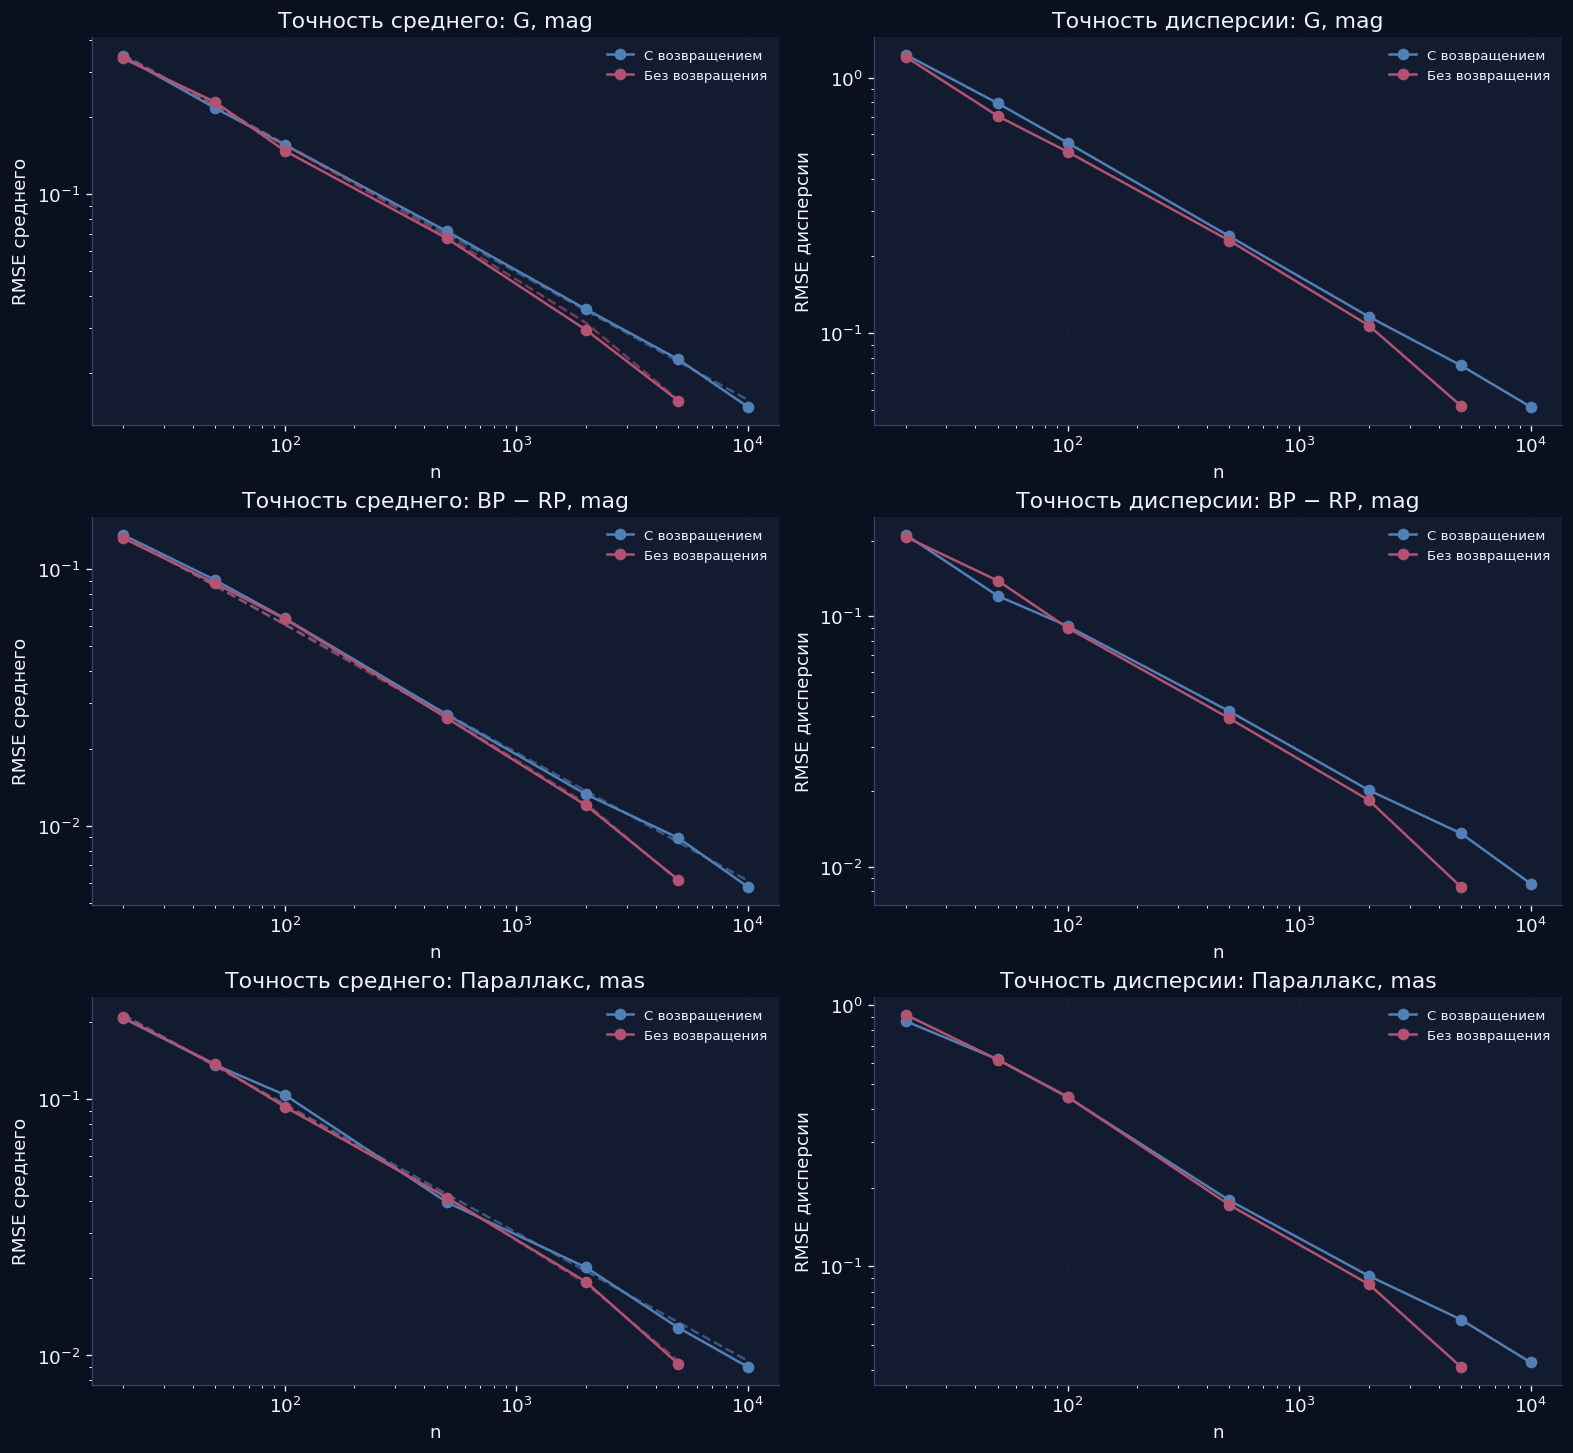

In [ ]:
# @title Повторные выборки: точность оценок для трёх величин

from IPython.display import display, HTML

sample_sizes = [20, 50, 100, 500, 2000, 5000, N]
REPEATS = 300
sampling_rows = []

rng = np.random.default_rng(SEED + 400)

for mode, replace in [
    ('С возвращением', True),
    ('Без возвращения', False)
]:
    for n in sample_sizes:
        mean_draws = np.empty((REPEATS, 3))
        var_draws = np.empty((REPEATS, 3))

        if not replace and n == N:
            mean_draws[:] = values.mean(axis=0)
            var_draws[:] = values.var(axis=0, ddof=1)
        else:
            for rep in range(REPEATS):
                idx = rng.choice(N, n, replace=replace)
                mean_draws[rep] = values[idx].mean(axis=0)
                var_draws[rep] = values[idx].var(axis=0, ddof=1)

        for j, key in enumerate(feature_keys):
            a = values[:, j]
            mu = a.mean()
            v = a.var(ddof=0)
            target = v if replace else a.var(ddof=1)

            finite_factor = 1.0 if replace else (N - n) / (N - 1)
            theory_se = np.sqrt(v / n * finite_factor)

            errors = mean_draws[:, j] - mu
            var_errors = var_draws[:, j] - target

            sampling_rows.append({
                'Отбор': mode,
                'n': n,
                'Характеристика': feature_labels[j],
                'R': REPEATS,
                'Смещение среднего': errors.mean(),
                'RMSE среднего': np.sqrt(np.mean(errors**2)),
                'SD средних': errors.std(ddof=1),
                'Теоретическая SE': theory_se,
                'Доля |ошибка среднего|>0.1': np.mean(
                    np.abs(errors) > 0.1
                    if key != 'Параллакс'
                    else np.abs(errors) > 0.1
                ),
                'Цель дисперсии': target,
                'Смещение дисперсии': var_errors.mean(),
                'RMSE дисперсии': np.sqrt(np.mean(var_errors**2))
            })

sampling_metrics = pd.DataFrame(sampling_rows)

sampling_metrics.to_csv(
    OUT / 'sampling_metrics_all_features.csv',
    index=False
)

display(
    sampling_metrics[
        [
            'Отбор',
            'n',
            'Характеристика',
            'Смещение среднего',
            'RMSE среднего',
            'SD средних',
            'Теоретическая SE',
            'Смещение дисперсии',
            'RMSE дисперсии'
        ]
    ].round(6).style
    .set_caption('Точность оценок при повторных выборках')
    .set_table_styles([
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('padding', '12px'),
                ('border-radius', '10px 10px 0 0')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#111827'),
                ('color', '#F8FAFC'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '10px'),
                ('border', '1px solid #D8D4F0'),
                ('text-align', 'center'),
                ('white-space', 'normal')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('color', '#1F2937'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '14px'),
                ('padding', '9px'),
                ('border-bottom', '1px solid #E5E7EB'),
                ('border-left', '1px solid #D8D4F0'),
                ('border-right', '1px solid #D8D4F0'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd)',
            'props': [('background-color', '#F5F3FF')]
        },
        {
            'selector': 'tbody tr:nth-child(even)',
            'props': [('background-color', '#FFFFFF')]
        },
        {
            'selector': 'table',
            'props': [
                ('border-collapse', 'separate'),
                ('border-spacing', '0'),
                ('border', '1px solid #D8D4F0'),
                ('border-radius', '10px'),
                ('overflow', 'hidden')
            ]
        }
    ])
    .hide(axis='index')
)

# Графики точности среднего и дисперсии
fig, axes = plt.subplots(
    3, 2,
    figsize=(13, 12),
    constrained_layout=True
)

for j, key in enumerate(feature_keys):
    for mode, color in [
        ('С возвращением', '#527fb5'),
        ('Без возвращения', '#b25371')
    ]:
        part = sampling_metrics[
            (sampling_metrics['Характеристика'] == feature_labels[j])
            & (sampling_metrics['Отбор'] == mode)
        ]

        nz = part[part['RMSE среднего'] > 0]

        axes[j, 0].plot(
            nz['n'],
            nz['RMSE среднего'],
            'o-',
            color=color,
            label=mode
        )
        axes[j, 0].plot(
            nz['n'],
            nz['Теоретическая SE'],
            '--',
            color=color,
            alpha=0.6
        )

        nzv = part[part['RMSE дисперсии'] > 0]

        axes[j, 1].plot(
            nzv['n'],
            nzv['RMSE дисперсии'],
            'o-',
            color=color,
            label=mode
        )

    axes[j, 0].set(
        xscale='log',
        yscale='log',
        xlabel='n',
        ylabel='RMSE среднего',
        title=f'Точность среднего: {feature_labels[j]}'
    )

    axes[j, 1].set(
        xscale='log',
        yscale='log',
        xlabel='n',
        ylabel='RMSE дисперсии',
        title=f'Точность дисперсии: {feature_labels[j]}'
    )

    for ax in axes[j]:
        ax.grid(alpha=0.15)
        ax.legend(frameon=False, fontsize=8)

fig.savefig(
    OUT / 'sampling_precision_all_features.png',
    bbox_inches='tight'
)
plt.show()

display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    font-size: 14px;
    color: #1F2937;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    margin-top: 12px;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 12px;
        font-weight: bold;
    ">
        Вывод по повторным выборкам
    </div>
    <div style="
        background: #F5F3FF;
        padding: 14px;
        line-height: 1.6;
    ">При увеличении размера выборки оценки в целом становятся точнее.
Например, при отборе без возвращения переход от 20 к 500 объектам
уменьшил RMSE среднего:<br>
для G — с <b>0.340 до 0.067 mag</b>;<br>
для цвета — с <b>0.132 до 0.026 mag</b>;<br>
для параллакса — с <b>0.208 до 0.041 mas</b>.<br><br>

В этих примерах ошибка уменьшилась примерно в пять раз.
По одной выборке мы могли бы получить случайно удачный
или неудачный результат, поэтому сравнивали 300 повторений.<br><br>

При выборе всех 10 000 объектов без возвращения получаем всю базу,
поэтому ошибка равна нулю. Эта строка есть в таблице,
но нулевые значения не показаны на логарифмических графиках.
При отборе с возвращением даже выборка из 10 000 строк
может содержать повторы, поэтому точное совпадение не гарантируется.<br><br>

Мы проверили, как размер и способ отбора влияют на точность оценок.
    </div>
</div>
"""))

[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
8. Проверка статистических гипотез
</h2></div>
"""))

<a id="hypotheses"></a>

В работе выполняем три типа проверок.

1. **В разделах 3–5** проверяем, согласуются ли контрольные данные с выбранной моделью распределения.
2. **В разделе 6** проверяем независимость каждой пары характеристик с помощью перестановочного теста, использующего коэффициент Спирмена.
3. **В разделе 9** проверяем нулевую модель случайного отбора: насколько необычны средние цвета и параллакса яркой группы по сравнению со случайными группами того же размера.

Уровень значимости заранее задаём равным $\alpha=0.05$. Это выбранная граница риска ошибочного отвержения верной нулевой гипотезы при выполнении условий проверки.

P-value показывает, насколько необычен наблюдаемый результат при нулевой гипотезе: вероятность получить столь же сильное или более сильное отклонение.

В каждой рассматриваемой группе проверок применяем поправку Холма [9]. Поэтому решение принимаем по скорректированному значению `p_Holm`:

- если `p_Holm < 0.05`, отвергаем нулевую гипотезу;
- если `p_Holm ≥ 0.05`, оснований для её отвержения недостаточно.

Второй результат не доказывает, что гипотеза верна. P-value также не является вероятностью истинности гипотезы.

В разделе 6 для всех трёх пар получили `p_Holm = 0.0015`. В разделе 9 для цвета и параллакса получили `p_Holm = 0.001`. Эти значения меньше 0,05, поэтому соответствующие нулевые гипотезы отвергаем.

Статистическая значимость не показывает силу связи или размер различия, поэтому вместе с p-value рассматриваем коэффициенты корреляции и разности средних.

[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
9. Эксперимент: что меняется при выборе самых ярких объектов
</h2></div>
"""))

<a id="selection"></a>

Проверяем отдельный вопрос: можно ли взять только самые яркие объекты и по ним судить о среднем цвете и параллаксе всей рабочей базы?

Выбираем 500 объектов с наименьшими G: меньшая звёздная величина соответствует большей наблюдаемой яркости.

Для сравнения 1999 раз равновероятно выбираем из базы по 500 строк без возвращения. Для каждой случайной группы вычисляем средние значения. Так видим, какие результаты обычно получаются при случайном отборе.

Затем сравниваем отклонение среднего яркой группы от среднего базы с отклонениями случайных групп. Для цвета и параллакса рассчитываем p-value методом Монте-Карло и применяем поправку Холма к двум проверкам.

Различие по самой G ожидается заранее: именно по ней отбирались объекты. Поэтому основной интерес представляют изменения двух других характеристик — цвета и параллакса.

Характеристика,Среднее базы,Среднее ярких 500,Разность,Сдвиг / σ базы,95% случайных средних: низ,95% случайных средних: верх,p_MC,p_Holm,Решение
"G, mag",18.939417,14.565663,-4.373754,-2.78165,18.799345,19.067568,nan,nan,Контроль отбора
"BP − RP, mag",1.620746,1.367696,-0.25305,-0.414632,1.572025,1.672904,0.0005,0.001,Отличается от случайной выборки
"Параллакс, mas",0.371944,0.870217,0.498273,0.523094,0.291434,0.449934,0.0005,0.001,Отличается от случайной выборки


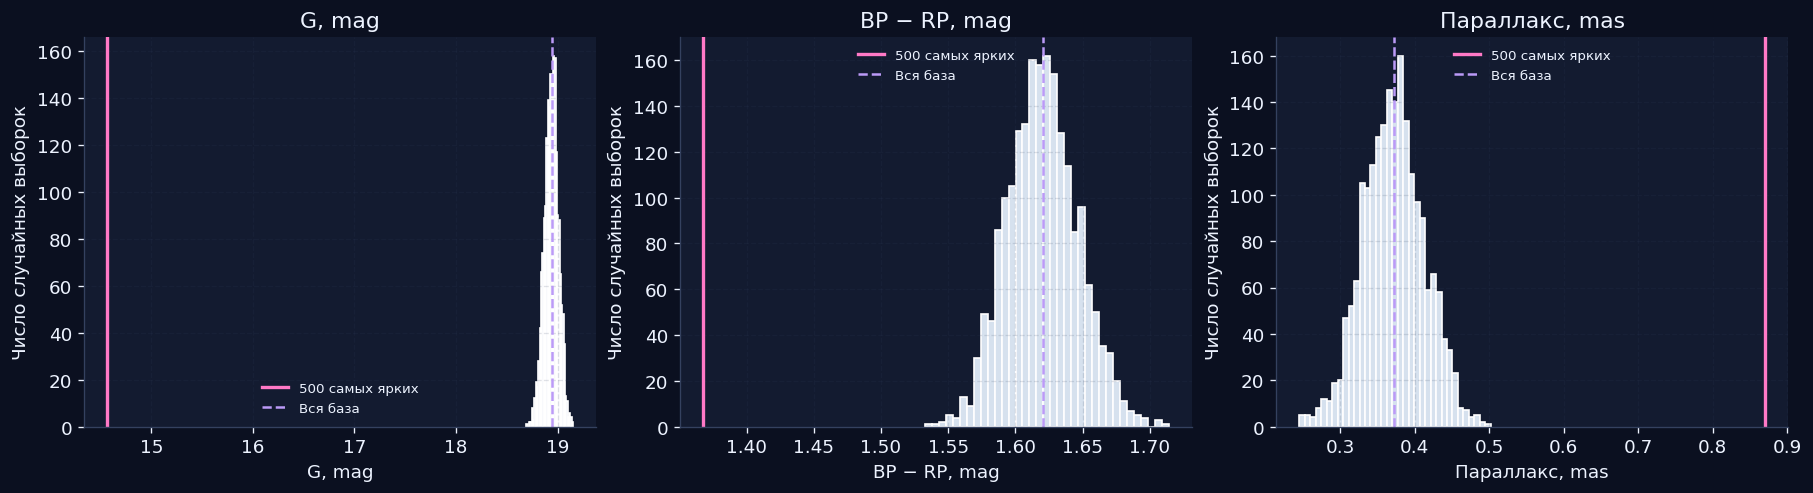

In [ ]:

# @title Яркостный отбор: сравнение со случайными выборками

BRIGHT_N = 500
SELECTION_REPEATS = 1999

bright_indices = np.argsort(values[:, 0], kind='stable')[:BRIGHT_N]
bright_values = values[bright_indices]

pop_means = values.mean(axis=0)
pop_stds = values.std(axis=0, ddof=0)

rng = np.random.default_rng(SEED + 500)
random_means = np.empty((SELECTION_REPEATS, 3))
random_medians = np.empty_like(random_means)
random_stds = np.empty_like(random_means)

for rep in range(SELECTION_REPEATS):
    idx = rng.choice(N, BRIGHT_N, replace=False)
    selected = values[idx]

    random_means[rep] = selected.mean(axis=0)
    random_medians[rep] = np.median(selected, axis=0)
    random_stds[rep] = selected.std(axis=0, ddof=1)

observed = np.abs(bright_values.mean(axis=0) - pop_means)

raw_p = []
for j in [1, 2]:
    raw_p.append(
        (1 + np.sum(
            np.abs(random_means[:, j] - pop_means[j]) >= observed[j]
        )) / (SELECTION_REPEATS + 1)
    )

holm_p = holm_adjust(raw_p)

selection_rows = []

for j, key in enumerate(feature_keys):
    low, high = np.quantile(random_means[:, j], [0.025, 0.975])

    selection_rows.append({
        'Характеристика': feature_labels[j],
        'Среднее базы': pop_means[j],
        'Среднее ярких 500': bright_values[:, j].mean(),
        'Разность': bright_values[:, j].mean() - pop_means[j],
        'Сдвиг / σ базы': (
            bright_values[:, j].mean() - pop_means[j]
        ) / pop_stds[j],
        '95% случайных средних: низ': low,
        '95% случайных средних: верх': high,
        'p_MC': np.nan if j == 0 else raw_p[j - 1],
        'p_Holm': np.nan if j == 0 else holm_p[j - 1],
        'Решение': (
            'Контроль отбора' if j == 0 else
            ('Отличается от случайной выборки'
             if holm_p[j - 1] < ALPHA
             else 'Недостаточно оснований для отличия')
        )
    })

selection_table = pd.DataFrame(selection_rows)

selection_table.to_csv(
    OUT / 'bright_selection_all_features.csv',
    index=False
)


# Отображение таблицы в HTML-стиле
from IPython.display import display, HTML
import html

selection_display = selection_table.round(6)

headers = ''.join(
    f'<th style="padding:14px;text-align:left;white-space:nowrap;">'
    f'{html.escape(str(col))}</th>'
    for col in selection_display.columns
)

rows = ''

for i, row in enumerate(
    selection_display.itertuples(index=False, name=None)
):
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'

    cells = ''.join(
        '<td style="padding:12px;border-bottom:1px solid #E5E7EB;'
        'white-space:nowrap;">'
        f'{html.escape(str(value))}</td>'
        for value in row
    )

    rows += f'<tr style="background:{bg};">{cells}</tr>'

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;">
  <div style="font-size:16px;font-weight:bold;color:#111827;
              margin-bottom:10px;">
    Результаты яркостного отбора
  </div>
  <div style="overflow-x:auto;border:1px solid #D8D4F0;
              border-radius:10px;">
    <table style="width:100%;border-collapse:separate;
                  border-spacing:0;font-size:14px;color:#1F2937;">
      <thead>
        <tr style="background:#111827;color:#F8FAFC;">
          {headers}
        </tr>
      </thead>
      <tbody>{rows}</tbody>
    </table>
  </div>
</div>
"""))


# Порог яркой группы
threshold = values[bright_indices, 0].max()

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;
            border:1px solid #D8D4F0;border-radius:10px;overflow:hidden;">
  <div style="background:#111827;color:#F8FAFC;padding:12px 16px;
              font-size:15px;font-weight:bold;">
    Критерий отбора
  </div>
  <div style="background:#F5F3FF;padding:14px 16px;color:#1F2937;
              font-size:14px;line-height:1.6;">
    Выбрано <b>{BRIGHT_N}</b> самых ярких объектов.<br>
    Порог яркости: <b>G ≤ {threshold:.4f} mag</b>.
    Чем меньше звёздная величина G, тем ярче объект.
  </div>
</div>
"""))


# Графики распределений средних случайных выборок
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
    constrained_layout=True
)

for j, key in enumerate(feature_keys):
    axes[j].hist(
        random_means[:, j],
        bins=35,
        color='#d6e1ee',
        edgecolor='white'
    )

    axes[j].axvline(
        bright_values[:, j].mean(),
        color=COLORS['bright'],
        lw=2,
        label='500 самых ярких'
    )

    axes[j].axvline(
        pop_means[j],
        color=COLORS['median'],
        ls='--',
        label='Вся база'
    )

    axes[j].set(
        xlabel=feature_labels[j],
        ylabel='Число случайных выборок',
        title=feature_labels[j]
    )

    axes[j].legend(frameon=False, fontsize=8)
    axes[j].grid(alpha=.15)

fig.savefig(
    OUT / 'bright_selection_all_features.png',
    bbox_inches='tight'
)
plt.show()


# Итоговый вывод
display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    margin: 20px 0;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    color: #1F2937;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 14px 18px;
        font-size: 16px;
        font-weight: bold;
    ">
        Вывод
    </div>
    <div style="
        background: #F5F3FF;
        padding: 16px 18px;
        font-size: 14px;
        line-height: 1.7;
    ">
        Отбор самых ярких объектов изменил обе проверяемые характеристики.<br><br>

Средний цвет BP − RP уменьшился
с <b>1.621 до 1.368 mag</b>, то есть на <b>0.253 mag</b>.
Средний измеренный параллакс увеличился
с <b>0.372 до 0.870 mas</b>, то есть на <b>0.498 mas</b>.<br><br>

Для сравнения: центральные 95% средних случайных групп
находились примерно от <b>1.572 до 1.673 mag</b> для цвета
и от <b>0.291 до 0.450 mas</b> для параллакса.
Средние яркой группы вышли за оба диапазона.
Для обеих проверок <b>p_Holm = 0.001</b>.<br><br>

Получается, что 500 самых ярких объектов отличаются
от обычной случайной группы того же размера.
Если использовать их средние для описания всей базы,
получим смещение по цвету и параллаксу.<br><br>

Когда мы оставили только самые яркие объекты, изменились и средний цвет, и средний параллакс. Поэтому по такой группе нельзя судить о средних значениях всей нашей базы.
    </div>
</div>
"""))


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
10. Зачем нужен генератор
</h2></div>
"""))

<a id="sprint2"></a>


<a id="sprint2"></a>

Генератор должен создавать значения, похожие на наблюдаемые значения одной характеристики. В основной части строим генератор для G, а затем проверяем тот же алгоритм отдельно на цвете и параллаксе.

Здесь важно различать две вещи:

- **PCG64** в NumPy — базовый генератор псевдослучайных чисел, который используется через `np.random.default_rng(SEED)` [5].
- **Наши методы** — алгоритмы, которые преобразуют равномерные псевдослучайные числа в значения нужной случайной величины.

PCG64 работает с внутренним состоянием, которое изменяется по определённому алгоритму. Упрощённо этот процесс можно записать так:

$$
s_{n+1}=(a s_n+c)\bmod 2^{128},
$$

где $s_n$ — текущее состояние генератора, $a$ и $c$ — параметры алгоритма.

Затем PCG64 дополнительно преобразует биты состояния, чтобы получить выходное число. При вызове `rng.random()` мы получаем псевдослучайное число из равномерного распределения:

$$
U\sim U(0,1).
$$

Но характеристики звёзд не распределены равномерно. Поэтому дальше используем методы обратной CDF и суперпозиции, которые позволяют получить значения с распределением, соответствующим нашей базе Gaia.

`seed` используется для инициализации генератора. Если использовать одинаковый `seed` и повторить вычисления в тех же условиях, получим ту же последовательность. Это удобно для проверки результатов, но одновременно показывает, что псевдослучайность не равна полной непредсказуемости.

Мы не выдаём сгенерированные значения за новые наблюдения звёзд. Генератор воспроизводит одномерные распределения рабочей базы. Если генерировать G, цвет и параллакс независимо, исходные зависимости между ними потеряются.


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
11. Математическое описание алгоритмов
</h2></div>
"""))


<a id="algorithms"></a>

Для генерации случайных величин мы выбрали два метода: обратную функцию распределения и суперпозицию. Оба метода используют равномерные псевдослучайные числа, полученные с помощью PCG64, но преобразуют их по-разному [4].

### Метод обратной функции

Идея метода заключается в том, что равномерно распределённое число можно преобразовать в значение случайной величины с нужным распределением.

Пусть $F(x)$ — функция распределения случайной величины $X$:

$$
F(x)=P(X\leq x).
$$

Если $U\sim U(0,1)$, то

$$
X=F^{-1}(U),
$$

где $F^{-1}$ — обратная функция распределения (в общем случае — обобщённая обратная функция).

Почему это работает:

$$
P(X\leq x)=P(F^{-1}(U)\leq x)=P(U\leq F(x))=F(x).
$$

Получается, что новая случайная величина действительно имеет заданное распределение.

В нашей работе точная функция распределения неизвестна, поэтому используем эмпирическую:

$$
F_N(x)=\frac{1}{N}\sum_{i=1}^{N}I(x_i\leq x),
$$

где $N$ — количество наблюдений, а $I$ — индикатор выполнения условия.

Для генерации сортируем исходные значения, получаем случайное число $U$ и выбираем элемент с индексом

$$
k=\lfloor UN\rfloor.
$$

Таким образом, мы фактически случайно выбираем значения из исходной базы с возвращением. Каждая позиция выбирается с вероятностью $1/N$. Если одинаковое значение встречается несколько раз, суммарная вероятность его получения увеличивается.

### Метод суперпозиции

Этот метод основан на представлении распределения в виде смеси нескольких распределений:

$$
F(x)=\sum_{j=1}^{m}w_jF_j(x),
\qquad
\sum_{j=1}^{m}w_j=1,
$$

где $F_j(x)$ — распределение отдельной компоненты, а $w_j$ — вероятность её выбора.

Сначала случайно выбирается компонента, затем из неё генерируется значение.

По формуле полной вероятности:

$$
P(X\leq x)=
\sum_{j=1}^{m}P(J=j)P(X\leq x\mid J=j)
=\sum_{j=1}^{m}w_jF_j(x)=F(x).
$$

В нашей реализации мы делим значения по медиане на две группы:

$$
A=\{x_i:x_i\leq \operatorname{Med}(X)\},
$$

$$
B=\{x_i:x_i>\operatorname{Med}(X)\}.
$$

Вероятности выбора групп определяем по их размерам:

$$
w_A=\frac{N_A}{N},\qquad w_B=\frac{N_B}{N}.
$$

Внутри каждой группы снова используем обратную эмпирическую CDF.

Вероятность выбрать конкретную позицию из первой группы равна

$$
P(I=i)=\frac{N_A}{N}\cdot\frac{1}{N_A}=\frac{1}{N}.
$$

Для второй группы получается то же самое.

То есть оба метода в нашей реализации дают одинаковое теоретическое распределение, хотя сами последовательности могут отличаться.

### Ограничения методов

Обратная функция достаточно проста для нашей базы, но не создаёт новых значений за пределами наблюдений. Для сложных теоретических распределений обратную функцию иногда трудно вычислить.

Суперпозиция удобна, если распределение состоит из нескольких компонентов. Однако в нашем случае деление по медиане условное: оно не означает, что мы выделили два физических типа звёзд. Поэтому суперпозиция не даёт нам принципиально нового распределения.

Кроме того, оба метода воспроизводят только распределение исходных данных и не учитывают погрешности измерений Gaia.

### Обзор дополнительных методов

| Метод | Где применяется | Сильная сторона | Ограничение |
|---|---|---|---|
| Обратная CDF | дискретные и непрерывные распределения с доступной CDF | простое доказательство | обратная функция может быть сложной |
| Суперпозиция | смеси распределений | удобно для неоднородных данных | нужны корректные веса |
| Нейман, принятие–отклонение | сложные плотности при известной огибающей | не требуется обратная CDF | бывают отказы, нужно доказать границу |
| Ratio of uniforms | непрерывные плотности | универсальный геометрический метод | нужны конечные границы области |

Два основных метода реализованы для эмпирического распределения G и применяются также к цвету BP−RP и параллаксу. Два дополнительных метода рассмотрены на примере стандартного нормального распределения $N(0,1)$.


Характеристика,Метод,n,Среднее базы,Среднее генератора,Медиана базы,Медиана генератора,s базы,s генератора,Q1 базы,Q1 генератора,Q3 базы,Q3 генератора,KS D,Wasserstein
"G, mag",Обратная CDF,10000,18.939417,18.935993,19.339181,19.34957,1.572438,1.574655,18.189339,18.163492,20.104594,20.11565,0.005,0.011401
"G, mag",Суперпозиция,10000,18.939417,18.943653,19.339181,19.336058,1.572438,1.550561,18.189339,18.206399,20.104594,20.086812,0.0091,0.016235
"BP − RP, mag",Обратная CDF,10000,1.620746,1.62293,1.530344,1.537374,0.610331,0.600385,1.190716,1.199891,1.952171,1.951023,0.0099,0.009073
"BP − RP, mag",Суперпозиция,10000,1.620746,1.621865,1.530344,1.527388,0.610331,0.619946,1.190716,1.18774,1.952171,1.946944,0.0064,0.006908
"Параллакс, mas",Обратная CDF,10000,0.371944,0.377237,0.312884,0.310185,0.952597,0.937356,0.024495,0.025753,0.662262,0.667872,0.0064,0.016696
"Параллакс, mas",Суперпозиция,10000,0.371944,0.378518,0.312884,0.30495,0.952597,0.932074,0.024495,0.023768,0.662262,0.661325,0.0082,0.012632


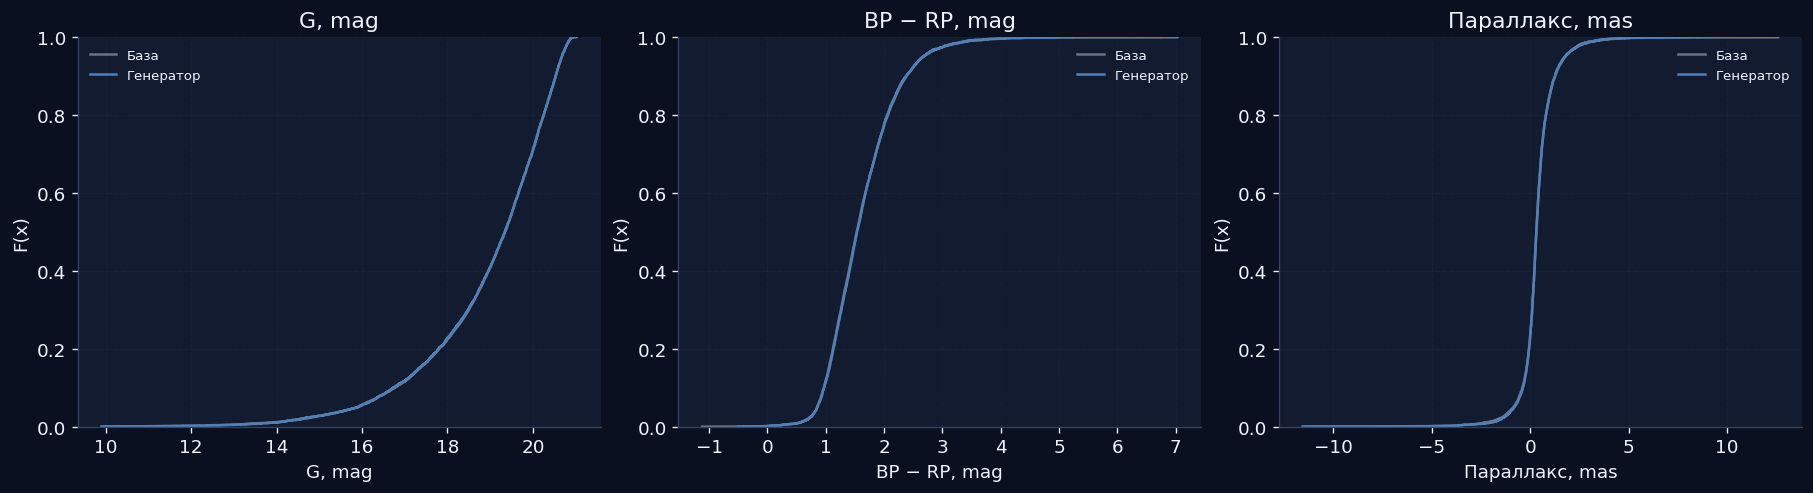

In [ ]:

# @title Два генератора по эмпирическому распределению

def validate_input(values, size):
    a = np.asarray(values, dtype=float)
    if a.ndim != 1 or a.size == 0 or not np.isfinite(a).all():
        raise ValueError('values должен быть непустым одномерным массивом конечных чисел')
    if isinstance(size, (bool, np.bool_)) or not isinstance(size, (int, np.integer)) or size < 0:
        raise ValueError('size должен быть неотрицательным целым числом')
    return a


def empirical_inverse_sample(values, size, rng):
    a = validate_input(values, size)
    ordered = np.sort(a)
    positions = np.floor(rng.random(size) * len(ordered)).astype(np.int64)
    return ordered[positions]


def empirical_superposition_sample(values, size, rng):
    a = validate_input(values, size)
    pivot = np.median(a)
    left = a[a <= pivot]
    right = a[a > pivot]

    if len(right) == 0:
        return empirical_inverse_sample(left, size, rng)

    choose_right = rng.random(size) >= len(left) / len(a)
    result = np.empty(size, dtype=float)
    result[~choose_right] = empirical_inverse_sample(
        left, int((~choose_right).sum()), rng
    )
    result[choose_right] = empirical_inverse_sample(
        right, int(choose_right.sum()), rng
    )
    return result


generator_rows = []
generated_by_method = {}

for feature_index, (key, label) in enumerate(zip(feature_keys, feature_labels)):
    source = values[:, feature_index]

    for method_index, (method_name, method) in enumerate([
        ('Обратная CDF', empirical_inverse_sample),
        ('Суперпозиция', empirical_superposition_sample)
    ]):
        generated = method(
            source,
            10000,
            np.random.default_rng(SEED + 700 + feature_index * 10 + method_index)
        )
        generated_by_method[(key, method_name)] = generated

        generator_rows.append({
            'Характеристика': label,
            'Метод': method_name,
            'n': len(generated),
            'Среднее базы': source.mean(),
            'Среднее генератора': generated.mean(),
            'Медиана базы': np.median(source),
            'Медиана генератора': np.median(generated),
            's базы': source.std(ddof=1),
            's генератора': generated.std(ddof=1),
            'Q1 базы': np.quantile(source, .25),
            'Q1 генератора': np.quantile(generated, .25),
            'Q3 базы': np.quantile(source, .75),
            'Q3 генератора': np.quantile(generated, .75),
            'KS D': stats.ks_2samp(source, generated).statistic,
            'Wasserstein': stats.wasserstein_distance(source, generated)
        })

generator_comparison = pd.DataFrame(generator_rows)

generator_comparison.to_csv(
    OUT / 'generator_comparison_all_features.csv',
    index=False
)


# Отображение таблицы в HTML-стиле
from IPython.display import display, HTML
import html

generator_display = generator_comparison.round(6)

headers = ''.join(
    f'<th style="padding:14px;text-align:left;white-space:nowrap;">'
    f'{html.escape(str(col))}</th>'
    for col in generator_display.columns
)

rows = ''

for i, row in enumerate(generator_display.itertuples(index=False, name=None)):
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'
    cells = ''.join(
        '<td style="padding:12px;border-bottom:1px solid #E5E7EB;'
        'white-space:nowrap;">'
        f'{html.escape(str(value))}</td>'
        for value in row
    )
    rows += f'<tr style="background:{bg};">{cells}</tr>'

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;">
  <div style="font-size:16px;font-weight:bold;color:#111827;
              margin-bottom:10px;">
    Сравнение эмпирических генераторов
  </div>
  <div style="overflow-x:auto;border:1px solid #D8D4F0;
              border-radius:10px;">
    <table style="width:100%;border-collapse:separate;
                  border-spacing:0;font-size:14px;color:#1F2937;">
      <thead>
        <tr style="background:#111827;color:#F8FAFC;">
          {headers}
        </tr>
      </thead>
      <tbody>{rows}</tbody>
    </table>
  </div>
</div>
"""))


# Главный генератор G и его распределение
main_generated = generated_by_method[('G', 'Обратная CDF')]

pd.DataFrame({
    'G_generated': main_generated
}).to_csv(OUT / 'generated_G.csv', index=False)


# Сравнение эмпирических функций распределения
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

for j, key in enumerate(feature_keys):
    source = values[:, j]
    gen = generated_by_method[(key, 'Обратная CDF')]

    axes[j].step(
        np.sort(source),
        np.arange(1, N + 1) / N,
        where='post',
        label='База',
        color='#697586'
    )
    axes[j].step(
        np.sort(gen),
        np.arange(1, len(gen) + 1) / len(gen),
        where='post',
        label='Генератор',
        color='#527fb5'
    )
    axes[j].set(
        xlabel=feature_labels[j],
        ylabel='F(x)',
        title=feature_labels[j],
        ylim=(0, 1)
    )
    axes[j].legend(frameon=False, fontsize=8)
    axes[j].grid(alpha=.15)

fig.savefig(
    OUT / 'generator_cdf_comparison_all_features.png',
    bbox_inches='tight'
)
plt.show()

from IPython.display import display, HTML

display(HTML("""
<div style="
    font-family: Arial, sans-serif;
    margin: 20px 0;
    border: 1px solid #D8D4F0;
    border-radius: 10px;
    overflow: hidden;
    color: #1F2937;
">
    <div style="
        background: #111827;
        color: #F8FAFC;
        padding: 14px 18px;
        font-size: 16px;
        font-weight: bold;
    ">
        Вывод
    </div>

    <div style="
        background: #F5F3FF;
        padding: 16px 18px;
        font-size: 14px;
        line-height: 1.7;
    ">
        <p>
        Обе реализации воспроизводят одномерные эмпирические распределения. Это воспроизведение конечной базы, а не прогноз свойств неизвестной звезды.
        </p>

    </div>
</div>
"""))



,Значение,Теория,Обратная CDF,Суперпозиция
0,1,0.125,0.1200,0.1193
1,2,0.250,0.2485,0.2483
2,3,0.125,0.1250,0.1259
3,4,0.375,0.3746,0.3803
4,5,0.125,0.1319,0.1262


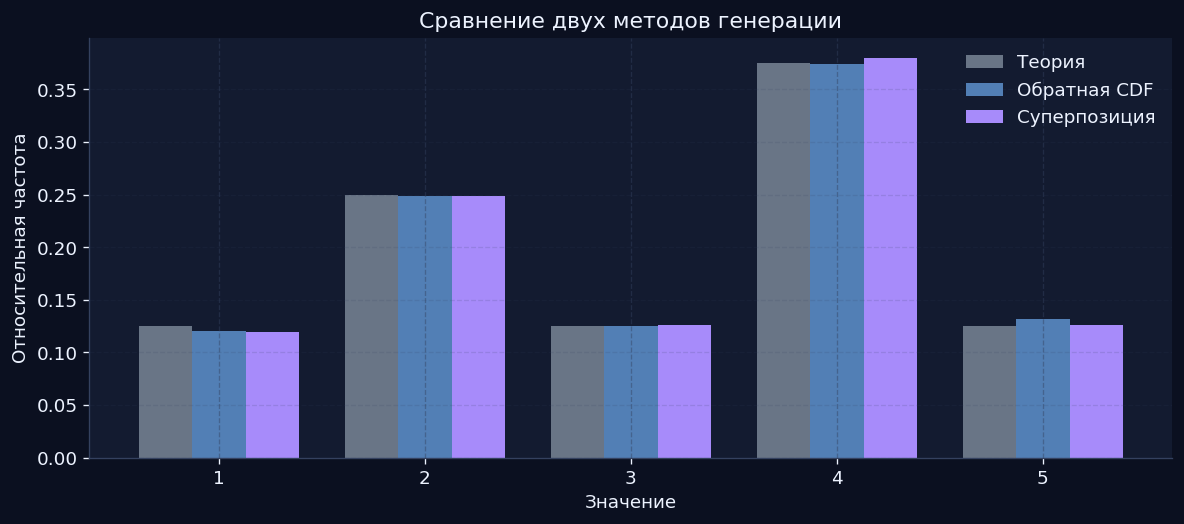

Максимальное отклонение от теории:
Обратная CDF: 0.0069
Суперпозиция: 0.0057


In [ ]:

# @title Проверка двух методов генерации

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Берём небольшую базу, где вероятности легко проверить вручную
data = np.array([1, 2, 2, 3, 4, 4, 4, 5])
n = 10000
seed = 2026

# Метод обратной CDF
rng1 = np.random.default_rng(seed)
ordered = np.sort(data)
indices = (rng1.random(n) * len(data)).astype(int)
inverse = ordered[indices]

# Метод суперпозиции
rng2 = np.random.default_rng(seed)
median = np.median(data)
left = data[data <= median]
right = data[data > median]

choose_right = rng2.random(n) >= len(left) / len(data)
superposition = np.empty(n, dtype=int)

superposition[~choose_right] = rng2.choice(
    left, size=(~choose_right).sum(), replace=True
)
superposition[choose_right] = rng2.choice(
    right, size=choose_right.sum(), replace=True
)

# Сравниваем теоретические вероятности с результатами
unique, counts = np.unique(data, return_counts=True)
theory = counts / len(data)

inverse_freq = np.array([
    np.mean(inverse == x) for x in unique
])
superposition_freq = np.array([
    np.mean(superposition == x) for x in unique
])

table = pd.DataFrame({
    'Значение': unique,
    'Теория': theory,
    'Обратная CDF': inverse_freq,
    'Суперпозиция': superposition_freq
})

display(table.round(4))

# Строим график в цветах лабораторной
x = np.arange(len(unique))
width = 0.26

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.bar(x - width, theory, width,
       label='Теория', color='#697586')
ax.bar(x, inverse_freq, width,
       label='Обратная CDF', color='#527fb5')
ax.bar(x + width, superposition_freq, width,
       label='Суперпозиция', color='#A78BFA')

ax.set_xticks(x)
ax.set_xticklabels(unique)
ax.set_xlabel('Значение')
ax.set_ylabel('Относительная частота')
ax.set_title('Сравнение двух методов генерации')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.15)

plt.tight_layout()
plt.show()

print('Максимальное отклонение от теории:')
print(f'Обратная CDF: {np.max(np.abs(inverse_freq - theory)):.4f}')
print(f'Суперпозиция: {np.max(np.abs(superposition_freq - theory)):.4f}')



**Вывод**

При генерации 10 000 значений оба метода должны давать частоты, близкие к теоретическим. Различия между ними возникают из-за случайных колебаний, а не из-за изменения исходного распределения.

Метод обратной CDF и суперпозиция при выбранном разбиении по медиане воспроизводят одно и то же эмпирическое распределение.

Для нашей задачи обратная CDF проще, поскольку суперпозиция добавляет этап выбора группы, но не даёт нового распределения.


,Метод,Seed,"Время, мс",Макс. отклонение
0,Обратная CDF,42,1.3809,0.0022
1,Суперпозиция,42,4.8243,0.0018
2,Обратная CDF,2026,1.0351,0.0021
3,Суперпозиция,2026,3.8390,0.0025
4,Обратная CDF,12345,0.8995,0.0024
5,Суперпозиция,12345,3.6180,0.0019


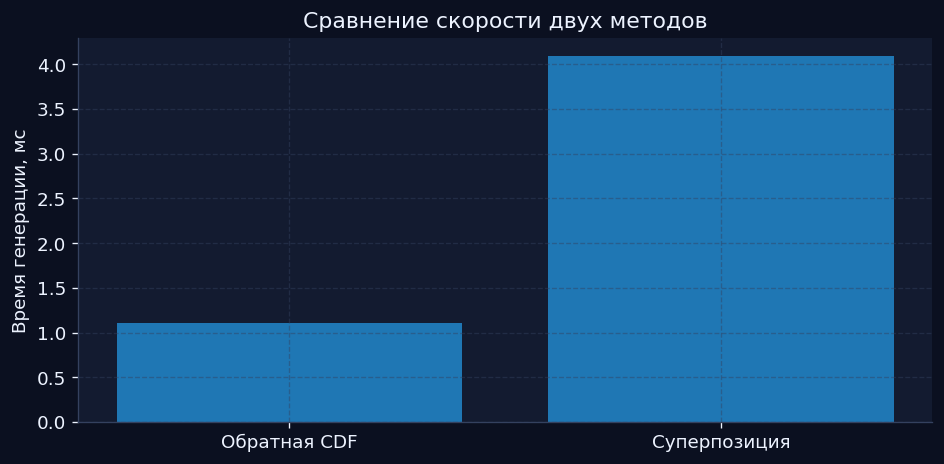

Seed 2026, первый запуск:  [2. 4. 3. 2. 2. 4. 5. 2. 4. 2. 5. 5.]
Seed 2026, второй запуск:  [2. 4. 3. 2. 2. 4. 5. 2. 4. 2. 5. 5.]
Seed 2027:                 [1. 3. 1. 3. 3. 4. 2. 4. 4. 1. 1. 3.]

Совпадение при одинаковом seed: True
Совпадение при разных seed: False


In [ ]:

# @title Скорость генераторов и проверка seed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter
from IPython.display import display

data = np.array([1, 2, 2, 3, 4, 4, 4, 5], dtype=float)
n = 100_000
seeds = [42, 2026, 12345]

def inverse_test(data, n, rng):
    ordered = np.sort(data)
    indices = (rng.random(n) * len(ordered)).astype(int)
    return ordered[indices]

def superposition_test(data, n, rng):
    pivot = np.median(data)
    left = data[data <= pivot]
    right = data[data > pivot]

    if len(right) == 0:
        return inverse_test(left, n, rng)

    choose_right = rng.random(n) >= len(left) / len(data)
    result = np.empty(n)
    result[~choose_right] = inverse_test(left, (~choose_right).sum(), rng)
    result[choose_right] = inverse_test(right, choose_right.sum(), rng)
    return result

methods = {
    'Обратная CDF': inverse_test,
    'Суперпозиция': superposition_test
}

unique, counts = np.unique(data, return_counts=True)
theory = counts / len(data)

rows = []

for seed in seeds:
    for name, method in methods.items():
        times = []
        errors = []

        for repeat in range(5):
            rng = np.random.default_rng(seed + repeat)

            start = perf_counter()
            generated = method(data, n, rng)
            times.append((perf_counter() - start) * 1000)

            frequencies = np.array([
                np.mean(generated == x) for x in unique
            ])
            errors.append(np.max(np.abs(frequencies - theory)))

        rows.append({
            'Метод': name,
            'Seed': seed,
            'Время, мс': np.median(times),
            'Макс. отклонение': np.mean(errors)
        })

results = pd.DataFrame(rows)
display(results.round(4))

# Сравнение скорости
speed = results.groupby('Метод')['Время, мс'].mean()

plt.figure(figsize=(8, 4))
plt.bar(speed.index, speed.values)
plt.ylabel('Время генерации, мс')
plt.title('Сравнение скорости двух методов')
plt.tight_layout()
plt.show()

# Воспроизводимость последовательностей
a = inverse_test(data, 12, np.random.default_rng(2026))
b = inverse_test(data, 12, np.random.default_rng(2026))
c = inverse_test(data, 12, np.random.default_rng(2027))

print('Seed 2026, первый запуск: ', a)
print('Seed 2026, второй запуск: ', b)
print('Seed 2027:                ', c)
print()
print('Совпадение при одинаковом seed:', np.array_equal(a, b))
print('Совпадение при разных seed:', np.array_equal(a, c))



**Сравнение скорости и воспроизводимости генераторов**


По результатам сравнения двух методов при одинаковом объёме генерации (100 000 значений) **обратная CDF** оказался быстрее. Для каждого метода использовали три значения `seed` и пять повторений. Оба алгоритма дали небольшие отклонения от теоретических вероятностей.

**Влияние начального значения генератора.** При одинаковом `seed = 2026` полученные последовательности полностью совпали. При изменении `seed` последовательность изменилась.

Это показывает, что псевдослучайная последовательность может иметь правильное статистическое распределение и при этом оставаться воспроизводимой, если известно начальное состояние генератора.

Однако воспроизводимость при известном `seed` сама по себе ещё не доказывает возможность восстановления неизвестного начального состояния.


In [ ]:

# @title Можно ли восстановить seed?

import numpy as np
import pandas as pd
from IPython.display import display

# Учебный эксперимент: seed выбирается из небольшого диапазона
secret_seed = 137
possible_seeds = range(1000)

# Наблюдаем первые 5 чисел генератора PCG64
observed = np.random.Generator(
    np.random.PCG64(secret_seed)
).integers(0, 1000000, size=5)

print("Наблюдаемая последовательность:", observed)

# Проверяем возможные seed и сравниваем последовательности
matches = []

for candidate in possible_seeds:
    test = np.random.Generator(
        np.random.PCG64(candidate)
    ).integers(0, 1000000, size=5)

    if np.array_equal(test, observed):
        matches.append(candidate)

display(pd.DataFrame({
    "Подходящие seed": matches
}))

print("Исходный seed:", secret_seed)
print("Найденный seed:", matches[0] if matches else "не найден")

# Проверим, что найденный seed позволяет воспроизвести
# следующее значение в той же последовательности
if matches:
    original = np.random.Generator(np.random.PCG64(secret_seed))
    recovered = np.random.Generator(np.random.PCG64(matches[0]))

    original.integers(0, 1000000, size=5)
    recovered.integers(0, 1000000, size=5)

    next_original = original.integers(0, 1000000)
    next_recovered = recovered.integers(0, 1000000)

    print("Следующее исходное число:", next_original)
    print("Следующее предсказанное число:", next_recovered)
    print("Совпадение:", next_original == next_recovered)


Наблюдаемая последовательность: [491136 858182 234907 275045 835323]


,Подходящие seed
0,137


Исходный seed: 137
Найденный seed: 137
Следующее исходное число: 426950
Следующее предсказанное число: 426950
Совпадение: True



**Исследование предсказуемости генератора**

Для проверки возможности восстановления начального значения генератора при известной части последовательности выбрали PCG64 и ограничили возможные значения `seed` диапазоном от 0 до 999. Затем сгенерировали пять чисел и попытались найти начальное значение перебором всех вариантов.

В результате удалось восстановить исходный `seed` и правильно предсказать следующее число.

Получается, что статистически случайная на вид последовательность может быть предсказуемой, если начальное значение выбирается из небольшого набора.

При этом наш эксперимент не означает, что любое начальное состояние PCG64 можно так же легко восстановить. Мы специально создали условия, при которых полный перебор был возможен.

Это объясняет, почему для защиты данных недостаточно получить числа с хорошим распределением. Важно также, насколько трудно предсказать внутреннее состояние генератора.



### Пример реальной уязвимости: Debian OpenSSL

В 2008 году была обнаружена уязвимость CVE-2008-0166 в генераторе случайных чисел OpenSSL, использовавшемся в Debian. Причина - ошибка при изменении исходного кода. Из-за нее генератор получал недостаточно случайных данных, поэтому количество возможных криптографических ключей сильно сократилось.

Наш эксперимент с небольшим диапазоном `seed` не повторяет саму ошибку Debian, но показывает похожую проблему: если число возможных начальных состояний слишком мало, их можно перебрать.То есть правильное распределение случайных чисел не гарантирует безопасность. Для криптографии важно не только статистическое качество генератора, но и непредсказуемость его состояния.

Источник: Debian Security Advisory DSA-1571-1, CVE-2008-0166.
https://lists.debian.org/debian-security-announce/2008/msg00152.html



### Квантовая случайность и защита данных

При изучении генераторов мы также рассмотрели их применение в криптографии.

PCG64 подходит для статистического моделирования, но не предназначен для защиты данных, поскольку его последовательность определяется внутренним состоянием.
Для криптографии используют специальные стойкие генераторы. Существуют также квантовые генераторы (QRNG), которые получают случайные числа на основе физических процессов.

Отдельное направление — постквантовая криптография (PQC). Её задача — защищать информацию с помощью алгоритмов, устойчивых к известным атакам, в том числе с использованием квантовых компьютеров.

Источник: [NIST — Post-Quantum Cryptography](https://www.nist.gov/cybersecurity-and-privacy/what-post-quantum-cryptography)


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
12. Автоматические проверки генераторов
</h2></div>
"""))


<a id="tests"></a>

Для проверки двух генераторов мы использовали семь автоматических тестов. Они помогают убедиться, что функции правильно обрабатывают входные данные и воспроизводят ожидаемые свойства распределения.

| Проверка | Что проверяем |
|---|---|
| Размер | Генератор возвращает столько значений, сколько мы запросили |
| Воспроизводимость | При одинаковом `seed` последовательности совпадают |
| Нулевой размер | При `size = 0` возвращается пустой массив |
| Одна точка | Если в базе одно значение, генератор возвращает только его |
| Исходные значения | Все результаты принадлежат исходной базе и являются конечными числами |
| Повторяющиеся значения | Проверяем частоту значения, которое встречается в базе несколько раз |
| Ошибочные аргументы | Некорректные данные должны вызывать `ValueError` |

Для проверки повторяющихся значений используем базу $[1,1,3]$. Теоретическая вероятность получить число 3 равна $1/3$. При генерации 60 000 значений проверяем, что наблюдаемая частота не слишком сильно отклоняется от неё.

Допустимое отклонение рассчитывается по формуле:

$$
\left|\hat p-\frac13\right|
<
6\sqrt{\frac{(1/3)(2/3)}{60000}}.
$$

Здесь $\hat p$ — полученная относительная частота числа 3.

Выбран достаточно широкий допуск, чтобы тест не срабатывал из-за обычных случайных колебаний.

Проверки показывают правильность работы функций в выбранных условиях, но не доказывают абсолютную случайность последовательностей или их криптографическую безопасность.


In [ ]:

# @title

class GeneratorTests(unittest.TestCase):
    methods = (empirical_inverse_sample, empirical_superposition_sample)

    def test_size(self):
        for method in self.methods:
            self.assertEqual(
                method([1., 2., 5.], 123, np.random.default_rng(1)).shape,
                (123,)
            )

    def test_reproducibility(self):
        for method in self.methods:
            a = method([1., 2., 5.], 1000, np.random.default_rng(15))
            b = method([1., 2., 5.], 1000, np.random.default_rng(15))
            np.testing.assert_array_equal(a, b)

    def test_empty(self):
        for method in self.methods:
            self.assertEqual(
                method([1., 2.], 0, np.random.default_rng(1)).shape,
                (0,)
            )

    def test_singleton(self):
        for method in self.methods:
            np.testing.assert_array_equal(
                method([7.], 100, np.random.default_rng(2)),
                np.full(100, 7.)
            )

    def test_support(self):
        for method in self.methods:
            d = method([-3., 1., 1., 9.], 5000, np.random.default_rng(11))
            self.assertTrue(
                np.isfinite(d).all() and np.isin(d, [-3., 1., 9.]).all()
            )

    def test_duplicate_weights(self):
        for method in self.methods:
            d = method([1., 1., 3.], 60000, np.random.default_rng(31))
            self.assertLess(
                abs(np.mean(d == 3) - 1/3),
                6 * np.sqrt((1/3) * (2/3) / 60000)
            )

    def test_invalid(self):
        for method in self.methods:
            for values_bad in [[], [[1., 2.]], [np.nan], [np.inf], 5.]:
                with self.assertRaises(ValueError):
                    method(values_bad, 1, np.random.default_rng(4))

            for size_bad in [-1, 1.5, True]:
                with self.assertRaises(ValueError):
                    method([1., 2.], size_bad, np.random.default_rng(4))


suite = unittest.defaultTestLoader.loadTestsFromTestCase(GeneratorTests)
result = unittest.TestResult()
suite.run(result)

if not result.wasSuccessful():
    raise AssertionError(result.errors + result.failures)

test_results = pd.DataFrame({
    'Проверка': [
        'Размер',
        'Воспроизводимость',
        'Нулевой размер',
        'Одна точка',
        'Диапазон исходной базы',
        'Повторяющиеся значения',
        'Ошибочные аргументы'
    ],
    'Результат': ['Пройдена'] * 7
})

test_results.to_csv(OUT / 'generator_tests.csv', index=False)

# Отображение в едином HTML-стиле
from IPython.display import display, HTML
import html

headers = ''.join(
    f'<th style="padding:14px;text-align:left;">'
    f'{html.escape(str(col))}</th>'
    for col in test_results.columns
)

rows = ''
for i, row in enumerate(test_results.itertuples(index=False, name=None)):
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'
    cells = ''.join(
        '<td style="padding:12px;border-bottom:1px solid #E5E7EB;">'
        f'{html.escape(str(value))}</td>'
        for value in row
    )
    rows += f'<tr style="background:{bg};">{cells}</tr>'

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;">
  <div style="font-size:16px;font-weight:bold;color:#111827;
              margin-bottom:10px;">
    Результаты автотестов генераторов
  </div>
  <div style="overflow-x:auto;border:1px solid #D8D4F0;
              border-radius:10px;">
    <table style="width:100%;border-collapse:separate;
                  border-spacing:0;font-size:14px;color:#1F2937;">
      <thead>
        <tr style="background:#111827;color:#F8FAFC;">
          {headers}
        </tr>
      </thead>
      <tbody>{rows}</tbody>
    </table>
  </div>
</div>
"""))

print('Пройдено проверок:', result.testsRun)


Проверка,Результат
Размер,Пройдена
Воспроизводимость,Пройдена
Нулевой размер,Пройдена
Одна точка,Пройдена
Диапазон исходной базы,Пройдена
Повторяющиеся значения,Пройдена
Ошибочные аргументы,Пройдена


Пройдено проверок: 7


### Учебные реализации двух дополнительных алгоритмов

Метод Неймана генерирует кандидата из простой плотности и принимает его с вероятностью, зависящей от отношения целевой плотности к огибающей. Метод отношений равномерных величин строит точку в специальной области и возвращает отношение координат. Оба метода используют равномерные числа PCG64 и служат примером алгоритмов для (N(0,1)), а не генератора Gaia. [4]


In [ ]:
# @title

def rejection_normal(size, seed):
    rng = np.random.default_rng(seed)
    out = []
    proposed = accepted = 0

    while sum(len(part) for part in out) < size:
        y = rng.laplace(size=4096)
        u = rng.random(4096)
        ok = u <= np.exp(-0.5 * (np.abs(y) - 1)**2)

        proposed += len(y)
        accepted += int(ok.sum())
        out.append(y[ok])

    return np.concatenate(out)[:size], accepted / proposed


def ratio_uniforms_normal(size, seed):
    rng = np.random.default_rng(seed)
    out = []
    proposed = accepted = 0

    vmax = np.sqrt(2 / np.e)

    while sum(len(part) for part in out) < size:
        u = np.maximum(
            rng.random(4096),
            np.nextafter(0., 1.)
        )
        v = rng.uniform(-vmax, vmax, 4096)
        y = v / u
        ok = 2 * np.log(u) <= -0.5 * y * y

        proposed += len(u)
        accepted += int(ok.sum())
        out.append(y[ok])

    return np.concatenate(out)[:size], accepted / proposed


demos = []

for name, fn, seed in [
    ('Нейман', rejection_normal, SEED + 900),
    ('Ratio of uniforms', ratio_uniforms_normal, SEED + 901)
]:
    generated, acceptance = fn(10000, seed)

    demos.append({
        'Метод': name,
        'Среднее': generated.mean(),
        's': generated.std(ddof=1),
        'KS D к N(0,1)': stats.kstest(generated, 'norm').statistic,
        'Доля принятых': acceptance
    })


algorithm_demos = pd.DataFrame(demos)

algorithm_demos.to_csv(
    OUT / 'additional_algorithm_demonstrations.csv',
    index=False
)


# Оформленная таблица результатов
from IPython.display import display, HTML
import html

algorithm_display = algorithm_demos.round(6)

headers = ''.join(
    f'<th style="padding:14px;text-align:left;white-space:nowrap;">'
    f'{html.escape(str(col))}</th>'
    for col in algorithm_display.columns
)

rows = ''

for i, row in enumerate(algorithm_display.itertuples(index=False, name=None)):
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'

    cells = ''.join(
        '<td style="padding:12px;border-bottom:1px solid #E5E7EB;">'
        f'{html.escape(str(value))}</td>'
        for value in row
    )

    rows += f'<tr style="background:{bg};">{cells}</tr>'

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;">
  <div style="font-size:16px;font-weight:bold;color:#111827;
              margin-bottom:10px;">
    Сравнение алгоритмов генерации стандартной нормали
  </div>
  <div style="overflow-x:auto;border:1px solid #D8D4F0;
              border-radius:10px;">
    <table style="width:100%;border-collapse:separate;
                  border-spacing:0;font-size:14px;color:#1F2937;">
      <thead>
        <tr style="background:#111827;color:#F8FAFC;">
          {headers}
        </tr>
      </thead>
      <tbody>{rows}</tbody>
    </table>
  </div>
</div>
"""))


Метод,Среднее,s,"KS D к N(0,1)",Доля принятых
Нейман,-0.01367,1.011932,0.011218,0.765625
Ratio of uniforms,-0.008538,1.000381,0.006128,0.729187


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
13. Итоговые выводы
</h2></div>
"""))

<a id="conclusions"></a>

1. Мы исследовали яркость G, цвет BP − RP и измеренный параллакс объектов Gaia DR3. Случайность в нашем опыте задаётся равновероятным выбором объекта из рабочей базы: до выбора неизвестно, какие значения попадутся.

2. Рабочую базу из 10 000 строк использовали как конечную генеральную совокупность для вычислительных экспериментов. По ней можно проверить точность оценок, потому что характеристики всей базы нам известны. При этом её состав зависит от первоначального отбора и доступности измерений Gaia.

3. Для каждой характеристики рассчитали описательные статистики, построили графики и выполнили нормализацию. Min–max и стандартизация помогают сравнивать масштабы, но сами по себе не делают распределение нормальным.

4. Сравнили несколько моделей распределения. Меньший BIC показывает преимущество модели среди рассмотренных вариантов, но не гарантирует её согласия с данными. Эмпирическое распределение описывает случайный выбор из нашей конечной базы.

5. Во всех трёх парах характеристик обнаружили статистически значимую, но слабую монотонную связь. Коэффициенты Спирмена составили примерно 0.144, −0.093 и 0.129. Поэтому наличие связи не означает, что по одной характеристике можно точно предсказать другую.

6. Повторные выборки показали, что с увеличением их размера оценки в целом становятся точнее. Например, при отборе без возвращения увеличение размера с 20 до 500 объектов уменьшило RMSE среднего примерно в пять раз для всех трёх характеристик. Повторения позволяют увидеть разброс результатов, который нельзя оценить по одной выбранной группе.

7. Отбор 500 самых ярких объектов изменил средний цвет с 1.621 до 1.368 mag, а средний измеренный параллакс — с 0.372 до 0.870 mas. Значит, такую группу нельзя использовать для описания средних характеристик всей базы без учёта смещения отбора.

8. Реализовали два способа генерации значений по эмпирическому распределению. Они воспроизводят одномерные распределения рабочей базы. Если генерировать три характеристики независимо, исходные связи между ними не сохранятся.

Следующая кодовая ячейка показывает численные результаты текущего запуска.

In [ ]:
# @title

from IPython.display import display, HTML
import pandas as pd
import numpy as np
import html

# Единый стиль таблиц
def styled_html_table(df, title, digits=6):
    df = df.copy()

    def format_value(value):
        if pd.isna(value):
            return "NaN"

        if isinstance(value, (int, np.integer)):
            return str(value)

        if isinstance(value, (float, np.floating)):
            return f"{value:.{digits}f}"

        return str(value)

    headers = "".join(
        f'<th style="padding:14px;text-align:left;'
        f'white-space:nowrap;">{html.escape(str(col))}</th>'
        for col in df.columns
    )

    rows = []
    for i, row in enumerate(df.itertuples(index=False, name=None)):
        background = "#F5F3FF" if i % 2 == 0 else "#FFFFFF"

        cells = "".join(
            '<td style="padding:12px;'
            'border-bottom:1px solid #E5E7EB;">'
            f'{html.escape(format_value(value))}</td>'
            for value in row
        )

        rows.append(
            f'<tr style="background:{background};">{cells}</tr>'
        )

    display(HTML(f"""
    <div style="font-family:Arial,sans-serif;margin:16px 0;">
      <div style="font-size:16px;font-weight:bold;color:#111827;
                  margin:0 0 10px 0;">
        {html.escape(title)}
      </div>
      <div style="overflow-x:auto;border:1px solid #D8D4F0;
                  border-radius:10px;">
        <table style="width:100%;border-collapse:separate;
                      border-spacing:0;font-size:14px;
                      color:#1F2937;">
          <thead>
            <tr style="background:#111827;color:#F8FAFC;">
              {headers}
            </tr>
          </thead>
          <tbody>
            {''.join(rows)}
          </tbody>
        </table>
      </div>
    </div>
    """))


# 1. ЧИСЛЕННЫЙ ИТОГ
summary_rows = []

for j, key in enumerate(feature_keys):
    a = values[:, j]

    summary_rows.append({
        "Характеристика": feature_labels[j],
        "N": N,
        "Среднее": a.mean(),
        "Медиана": np.median(a),
        "s": a.std(ddof=1),
        "Дисперсия": a.var(ddof=1)
    })

styled_html_table(
    pd.DataFrame(summary_rows),
    "ЧИСЛЕННЫЙ ИТОГ"
)


# 2. Зависимости
styled_html_table(
    dependence_table[
        ["Пара", "Spearman ρ", "p_Holm", "Решение"]
    ].round(6),
    "Зависимости"
)


# 3. Яркостный отбор
styled_html_table(
    selection_table[
        [
            "Характеристика",
            "Среднее базы",
            "Среднее ярких 500",
            "Разность",
            "p_Holm",
            "Решение"
        ]
    ].round(6),
    "Яркостный отбор"
)


# 4. Сравнение генераторов
styled_html_table(
    generator_comparison[
        [
            "Характеристика",
            "Метод",
            "Среднее базы",
            "Среднее генератора",
            "KS D",
            "Wasserstein"
        ]
    ].round(6),
    "Генератор"
)


Характеристика,N,Среднее,Медиана,s,Дисперсия
"G, mag",10000,18.939417,19.339181,1.572438,2.472561
"BP − RP, mag",10000,1.620746,1.530344,0.610331,0.372503
"Параллакс, mas",10000,0.371944,0.312884,0.952597,0.907441


Пара,Spearman ρ,p_Holm,Решение
G — BP−RP,0.143834,0.001500,Независимость отвергается
G — Параллакс,-0.093355,0.001500,Независимость отвергается
BP−RP — Параллакс,0.128856,0.001500,Независимость отвергается


Характеристика,Среднее базы,Среднее ярких 500,Разность,p_Holm,Решение
"G, mag",18.939417,14.565663,-4.373754,NaN,Контроль отбора
"BP − RP, mag",1.620746,1.367696,-0.253050,0.001000,Отличается от случайной выборки
"Параллакс, mas",0.371944,0.870217,0.498273,0.001000,Отличается от случайной выборки


Характеристика,Метод,Среднее базы,Среднее генератора,KS D,Wasserstein
"G, mag",Обратная CDF,18.939417,18.935993,0.005000,0.011401
"G, mag",Суперпозиция,18.939417,18.943653,0.009100,0.016235
"BP − RP, mag",Обратная CDF,1.620746,1.622930,0.009900,0.009073
"BP − RP, mag",Суперпозиция,1.620746,1.621865,0.006400,0.006908
"Параллакс, mas",Обратная CDF,0.371944,0.377237,0.006400,0.016696
"Параллакс, mas",Суперпозиция,0.371944,0.378518,0.008200,0.012632


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
14. Карта требований лабораторной работы
</h2></div>
"""))

In [ ]:
# @title

from IPython.display import display, HTML
import html

criteria = [
    (
        "Основное: датасет по направлению",
        "Раздел 1: Gaia DR3, источник данных и способ отбора"
    ),
    (
        "Основное: три случайные величины",
        "Разделы 3–5: G, BP − RP и измеренный параллакс"
    ),
    (
        "Основное: обоснование случайности",
        "Раздел 2: равновероятный выбор объекта из рабочей базы"
    ),
    (
        "Основное: описательная статистика",
        "Разделы 3–5: статистики, гистограммы, boxplot и ECDF"
    ),
    (
        "Основное: нормализация",
        "Разделы 3–5: min–max и стандартизация"
    ),
    (
        "Основное: исследование зависимости",
        "Раздел 6: Пирсон, Спирмен и перестановочная проверка"
    ),
    (
        "Основное: генеральная совокупность и выборки",
        "Раздел 7: рабочая база и меньшие случайные выборки"
    ),
    (
        "Выборки с возвращением и без возвращения",
        "Раздел 7: объяснение способов отбора и сравнение результатов"
    ),
    (
        "Основное: эмпирическое исследование точности оценок",
        "Раздел 7: смещение и RMSE при разных размерах выборки"
    ),
    (
        "Основное: статистические гипотезы",
        "Разделы 3–9: модели распределений, зависимости и яркостный отбор"
    ),
    (
        "Основное: математическая база распределений",
        "Разделы 3–5: модели; пояснения"
    ),
    (
        "Генерация значений по распределению",
        "Разделы 10–11: эмпирические генераторы"
    ),
    (
        "Обоснование алгоритмов генерации",
        "Раздел 11: обратный метод и суперпозиция"
    ),
    (
        "Сравнение исходных и сгенерированных данных",
        "Раздел 11: статистики, KS D и расстояние Вассерштейна"
    ),
    (
        "Доп.: другой алгоритм генерации",
        "Раздел 11: суперпозиция в дополнение к обратному методу"
    ),
    (
        "Доп.: автоматические проверки генератора",
        "Раздел 12: семь тестов для двух реализаций"
    ),
    (
        "Доп.: исследование дополнительных алгоритмов",
        "Раздел 12: принятие–отклонение и ratio of uniforms для N(0,1)"
    ),
    (
        "Доп.: рассмотрение разных распределений",
        "Разделы 3–5: нормальное, Лапласа и асимметричное нормальное"
    ),
    (
        "Доп.: приведение к стандартному нормальному",
        "Стандартизация выполнена; нормальность преобразованных данных этим не доказана"
    ),
    (
        "Доп.: табличное представление метрик",
        "Таблицы результатов и сохранение CSV"
    ),
    (
        "Доп.: список литературы",
        "Раздел 15: источники данных, методов и программных средств"
    ),
    (
        "Доп.: версионирование",
        "Подтверждается репозиторием GitHub и историей коммитов"
    ),
    (
        "Дополнительный эксперимент команды: смещение отбора",
        "Раздел 9: сравнение самых ярких объектов со случайными группами"
    ),
]

rows = ""
for i, (requirement, location) in enumerate(criteria):
    bg = "#F5F3FF" if i % 2 == 0 else "#FFFFFF"
    rows += f"""
    <tr style="background:{bg};">
        <td style="padding:12px; border-bottom:1px solid #E5E7EB;">
            {i + 1}
        </td>
        <td style="padding:12px; border-bottom:1px solid #E5E7EB;">
            {html.escape(requirement)}
        </td>
        <td style="padding:12px; border-bottom:1px solid #E5E7EB;">
            {html.escape(location)}
        </td>
    </tr>
    """

display(HTML(f"""
<div style="font-family:Arial,sans-serif; margin:16px 0;">
<h3 style="color:#111827; margin-bottom:10px;">
    Критерии выполнения лабораторной работы
</h3>
<table style="
    width:100%;
    border-collapse:separate;
    border-spacing:0;
    border-radius:10px;
    overflow:hidden;
    border:1px solid #D8D4F0;
    font-size:14px;
    color:#1F2937;
">
<thead>
<tr style="background:#111827; color:#F8FAFC;">
    <th style="padding:14px; text-align:left;">№</th>
    <th style="padding:14px; text-align:left;">Требование</th>
    <th style="padding:14px; text-align:left;">Где выполнено</th>
</tr>
</thead>
<tbody>{rows}</tbody>
</table>

<div style="
    margin-top:14px;
    padding:12px;
    background:#F5F3FF;
    border-left:4px solid #A78BFA;
    color:#1F2937;
">
    <b>История версий:</b>
    Коммиты создаются в GitHub.
</div>
</div>
"""))


№,Требование,Где выполнено
1,Основное: датасет по направлению,"Раздел 1: Gaia DR3, источник данных и способ отбора"
2,Основное: три случайные величины,"Разделы 3–5: G, BP − RP и измеренный параллакс"
3,Основное: обоснование случайности,Раздел 2: равновероятный выбор объекта из рабочей базы
4,Основное: описательная статистика,"Разделы 3–5: статистики, гистограммы, boxplot и ECDF"
5,Основное: нормализация,Разделы 3–5: min–max и стандартизация
6,Основное: исследование зависимости,"Раздел 6: Пирсон, Спирмен и перестановочная проверка"
7,Основное: генеральная совокупность и выборки,Раздел 7: рабочая база и меньшие случайные выборки
8,Выборки с возвращением и без возвращения,Раздел 7: объяснение способов отбора и сравнение результатов
9,Основное: эмпирическое исследование точности оценок,Раздел 7: смещение и RMSE при разных размерах выборки
10,Основное: статистические гипотезы,"Разделы 3–9: модели распределений, зависимости и яркостный отбор"


[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)

In [ ]:
#@title
from IPython.display import display, HTML

display(HTML("""
<div style="background:#111827;color:#F8FAFC;padding:20px 24px;
border-left:5px solid #A78BFA;border-radius:10px;
font-family:Arial,sans-serif;box-sizing:border-box;">
<h2 style="color:#F8FAFC;margin:0;font-size:23px;font-weight:700;line-height:1.5;">
15. Литература и источники
</h2></div>
"""))

<a id="references"></a>

1. ESA / Gaia / DPAC. [Gaia DR3: описание таблицы `gaiadr3.gaia_source`](https://gea.esac.esa.int/archive/documentation/GDR3/Gaia_archive/chap_datamodel/sec_dm_main_source_catalogue/ssec_dm_gaia_source.html).

   Определения столбцов, единицы измерения и описание `random_index`. Используется в разделе 1 при объяснении данных и способа отбора.

2. Gaia Collaboration, Vallenari A. et al. (2023). [Gaia Data Release 3: Summary of the content and survey properties](https://doi.org/10.1051/0004-6361/202243940). *Astronomy & Astrophysics*, 674, A1.

   Общее описание Gaia DR3 и содержащихся в нём астрометрических и фотометрических данных. Используется в разделе 1.

3. Luri X. et al. (2018). [Gaia Data Release 2: Using Gaia parallaxes](https://doi.org/10.1051/0004-6361/201832964). *Astronomy & Astrophysics*, 616, A9.

   Объяснение измеренного параллакса, появления отрицательных оценок и смещения при их удалении. Используются общие принципы работы с параллаксами, а не численные характеристики точности DR2.

4. Devroye L. (1986). [Non-Uniform Random Variate Generation](https://luc.devroye.org/rnbookindex.html). Springer.

   Математические принципы генерации: обратный метод — глава II, §2; принятие–отклонение — глава II, §3; суперпозиция — глава II, §4; отношения равномерных величин — глава IV, §7. Используется в разделах 11–12 для объяснения алгоритмов, реализованных на Python.

5. NumPy Developers. [PCG64](https://numpy.org/doc/stable/reference/random/bit_generators/pcg64.html); [Generator и default_rng](https://numpy.org/doc/stable/reference/random/generator.html).

   Документация базового генератора псевдослучайных чисел и интерфейса `np.random.default_rng`. Используется в разделе 10 и при организации воспроизводимых вычислений.

6. SciPy Developers. [Statistical functions — scipy.stats](https://docs.scipy.org/doc/scipy/reference/stats.html).

   Документация распределений, статистических функций, коэффициентов корреляции и критериев согласия. Соответствующие функции вызываются в коде разделов 3–6 и 11–12.

7. SciPy Developers. [Permutation tests — scipy.stats.permutation_test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).

   Методический источник для перемешивания соответствий между наблюдениями и добавления единицы при расчёте перестановочного p-value. Используется в разделе 6. Сам тест реализован собственным циклом; функция `scipy.stats.permutation_test` непосредственно не вызывается.

8. Penn State. [STAT 506: Estimating Population Mean and Total under SRS](https://online.stat.psu.edu/stat506/Lesson01).

   Формулы дисперсии выборочного среднего и поправки на конечную совокупность. Используется в разделе 7 с учётом различий в определении дисперсии через делитель N или N−1.

9. R Core Team. [Adjust P-values for Multiple Comparisons — p.adjust](https://stat.ethz.ch/R-manual/R-patched/library/stats/html/p.adjust.html).

   Объяснение поправки Холма и контроля риска хотя бы одного ложного отвержения в группе проверок. Используется в разделах 6 и 8. Расчёт выполняется собственной функцией `holm_adjust` на Python; R в работе не используется.

10. ESA. [Gaia Data Release 3: contents summary](https://www.cosmos.esa.int/web/gaia/dr3).

    Период наблюдений, на которых основан Gaia DR3: с 25 июля 2014 года по 28 мая 2017 года, 34 месяца. Используется в разделе 1.

11. ESA. [Gaia Mission Science Performance](https://www.cosmos.esa.int/web/gaia/science-performance).

    Описание фотометрических каналов G, BP и RP и зависимости фотометрической точности от яркости. Используется в разделе 1. Для этих пояснений рассматривается раздел о фотометрии на основе Gaia EDR3/DR3, а не численные прогнозы для DR4/DR5.

12. Debian Security Team. [DSA-1571-1: OpenSSL — predictable random number generator](https://lists.debian.org/debian-security-announce/2008/msg00152.html). Уязвимость CVE-2008-0166. Используется в разделе 11 при исследовании предсказуемости и криптографических рисков.

13. NIST. [What Is Post-Quantum Cryptography?](https://www.nist.gov/cybersecurity-and-privacy/what-post-quantum-cryptography). Используется в разделе 11 для объяснения постквантовой криптографии.

14. Hollands M. A., Gänsicke B. T., Tremblay P.-E., Koester D. (2026).
[Any colour you like: The diverse chromaticities of white dwarfs](https://arxiv.org/abs/2610.18966).
Препринт arXiv:2610.18966. Источник примера WD J1330+6435
и рисунка со спектрами в разделе 4.

In [ ]:
# @title

params = {
    'seed': SEED,
    'rows': N,
    'source_sha256': PROVENANCE['raw_sha256'],
    'sampling_repeats': REPEATS,
    'permutation_repeats': B_PERM,
    'selection_repeats': SELECTION_REPEATS,
    'alpha': ALPHA,
    'generator_tests': result.testsRun,
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scipy': __import__('scipy').__version__
}

# Сохраняем JSON, как и раньше
(OUT / 'analysis_parameters.json').write_text(
    json.dumps(params, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

# Отображаем параметры в едином HTML-стиле
from IPython.display import display, HTML
import html

rows = ''

for i, (key, value) in enumerate(params.items()):
    bg = '#F5F3FF' if i % 2 == 0 else '#FFFFFF'

    rows += f"""
    <tr style="background:{bg};">
      <td style="padding:12px;border-bottom:1px solid #E5E7EB;">
        <code>{html.escape(str(key))}</code>
      </td>
      <td style="padding:12px;border-bottom:1px solid #E5E7EB;
                 overflow-wrap:anywhere;">
        {html.escape(str(value))}
      </td>
    </tr>
    """

display(HTML(f"""
<div style="font-family:Arial,sans-serif;margin:16px 0;">
  <div style="font-size:16px;font-weight:bold;color:#111827;
              margin-bottom:10px;">
    Параметры воспроизводимости
  </div>
  <div style="overflow-x:auto;border:1px solid #D8D4F0;
              border-radius:10px;">
    <table style="width:100%;border-collapse:separate;
                  border-spacing:0;font-size:14px;color:#1F2937;">
      <thead>
        <tr style="background:#111827;color:#F8FAFC;">
          <th style="padding:14px;text-align:left;">Параметр</th>
          <th style="padding:14px;text-align:left;">Значение</th>
        </tr>
      </thead>
      <tbody>{rows}</tbody>
    </table>
  </div>
</div>
"""))


Параметр,Значение
seed,20261020
rows,10000
source_sha256,4155ca1040aebde678e5667fccd5426eadb58f7ce6797b9f23201b8782545757
sampling_repeats,300
permutation_repeats,1999
selection_repeats,1999
alpha,0.05
generator_tests,7
numpy,2.1.3
pandas,2.2.3


**Проверка данных по исходному каталогу**

Для проверки выбрали три объекта из начала, середины и конца нашего CSV. Нашли их в официальном архиве Gaia по `source_id` и сравнили яркость G, цвет BP − RP и параллакс. Все девять значений совпали. Ошибок переноса в проверенных записях не обнаружили; остальные строки таким способом не проверяли.

[Вернуться к оглавлению](#scrollTo=rDteLyWqGMZE&line)